# Check results

In [1]:
import numpy as np
import xarray as xr
import sys
sys.path.append("path/to/MISOMIP2")
import misomip2.preproc as mp
import os
from datetime import datetime
import glob

startTime = datetime.now()
print(startTime)

from dask.distributed import Client
import sys

import logging
logging.captureWarnings(True)
logging.getLogger('py.warnings').setLevel(logging.ERROR)


2026-10-13 20:55:33.916581


In [ ]:
client = Client()

# choose a location to save - ideally on gdata
save_dir = '/path/to/'
###############################
#### get run count argument that was passed to python script ####

startoutput = 66 #int(sys.argv[1])#(year-1980)*12
endoutput = startoutput + 1

np.seterr(divide='ignore', invalid='ignore')

reg='Weddell' # 'Amundsen' or 'Weddell'

data_dir='/path/to/original/data/'
missval=9.969209968386869e36 # missing value in created netcdf files

epsfr=1. # cut sea, sea-ice or ice-shelf fractions below epsfr (in %)
         # (useful to avoid extreme values that can occur with very small fractions)

filmis=False  # keep False (may become a deprecitated option)
              # if True, will fill nans (missing values in input file or values that can't be triangulated) 
              # through nearest-neighbor interpolation. This can be useful for the edges of non-structured grids.

print('Opening saved data ',save_dir+'oce_'+str(startoutput)+'_'+str(endoutput)+'.nc')
        
oce = xr.open_mfdataset(save_dir+'oce_'+str(startoutput)+'_'+str(endoutput)+'.nc',)#
                        #decode_coords=False,
                        #decode_timedelta=True,
                        #mask_and_scale = False,
                        #parallel=True)
model = 'MOM6'; abc='a'; exp='OceanW-hind'; institute = 'ANU'

In [3]:
import matplotlib.pyplot as plt

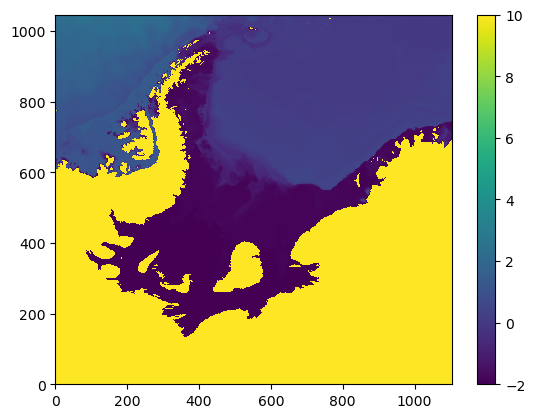

In [4]:
plt.pcolormesh(np.reshape(oce.THETAO.isel(z = 70,time =0).values,(1046, 1104)),
               vmax = 10, vmin = -2
              )
plt.colorbar()


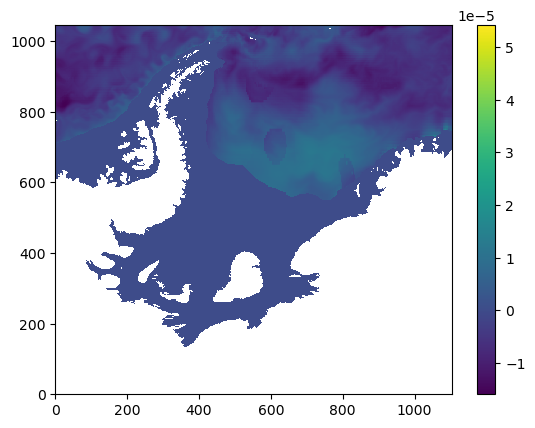

In [5]:
plt.pcolormesh(np.reshape(oce.WFOCORR.isel(time =0).values,(1046, 1104)),
               #vmax = 10, vmin = -2
              )
plt.colorbar()


salt restoring is a bit weird: It looks fine in `oce`, but somewhere in the regridding it collects a lot of NaNs? Weird, because it gets processed like other open ocean variables.

### Plot to check vert regridding looks ok

(5000.0, 0.0)

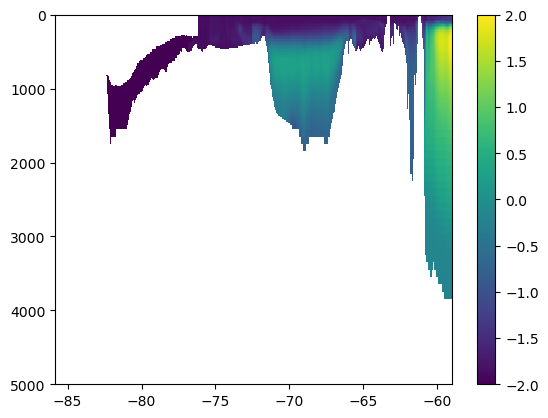

In [6]:
plt.pcolormesh(np.reshape(oce.latT.values,(1046, 1104))[:,430],oce.z.values,
                np.reshape(oce.THETAO.isel(time =0).values,(113,1046, 1104))[:,:,430]*np.where(
                    (np.reshape(oce.LEVOFT.values,(113,1046, 1104))[:,:,430]>0),1,np.nan),
                vmax = 2, vmin = -2
                )
plt.colorbar()
plt.ylim(5000,0)

(5000.0, 0.0)

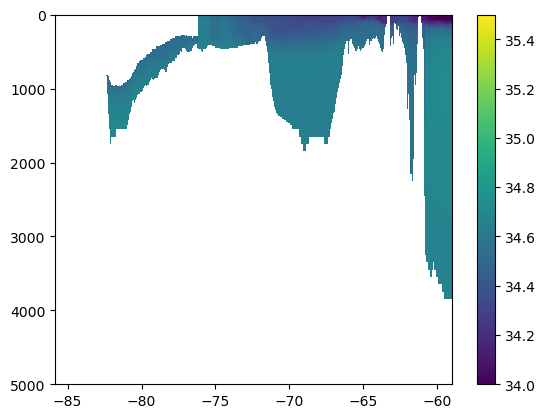

In [7]:
plt.pcolormesh(np.reshape(oce.latT.values,(1046, 1104))[:,430],oce.z.values,
                np.reshape(oce.SO.isel(time =0).values,(113,1046, 1104))[:,:,430]*np.where(
                    (np.reshape(oce.LEVOFT.values,(113,1046, 1104))[:,:,430]>0),1,np.nan),
                vmax = 35.5, vmin = 34
                )
plt.colorbar()
plt.ylim(5000,0)

## Manually check results after processing to see if they look similar enough to original model data

In [8]:
ds = xr.open_mfdataset('/path/to/Oce3d_ANU_MOM6_a_OceanW-hind_198507-198508.nc')

In [9]:
ds

<xarray.Dataset> Size: 41MB
Dimensions:      (time: 2, lev: 12, lat: 251, lon: 271)
Coordinates:
  * time         (time) datetime64[ns] 16B 1985-07-16T12:00:00 1985-08-16T12:...
  * lev          (lev) float32 48B 0.0 100.0 200.0 300.0 ... 900.0 1e+03 1.5e+03
  * lat          (lat) float32 1kB -85.0 -84.9 -84.8 -84.7 ... -60.2 -60.1 -60.0
  * lon          (lon) float32 1kB -90.0 -89.67 -89.33 ... -0.3333 -1.279e-12
Data variables: (12/28)
    so           (time, lev, lat, lon) float32 7MB dask.array<chunksize=(1, 12, 251, 271), meta=np.ndarray>
    thetao       (time, lev, lat, lon) float32 7MB dask.array<chunksize=(1, 12, 251, 271), meta=np.ndarray>
    uo           (time, lev, lat, lon) float32 7MB dask.array<chunksize=(1, 12, 251, 271), meta=np.ndarray>
    vo           (time, lev, lat, lon) float32 7MB dask.array<chunksize=(1, 12, 251, 271), meta=np.ndarray>
    tauuo        (time, lat, lon) float32 544kB dask.array<chunksize=(1, 251, 271), meta=np.ndarray>
    tauvo        (time, lat, lon) float32 544kB dask.array<chunksize=(1, 251, 271), meta=np.ndarray>
    ...           ...
    siv          (time, lat, lon) float32 544kB dask.array<chunksize=(1, 251, 271), meta=np.ndarray>
    levof        (lev, lat, lon) float32 3MB dask.array<chunksize=(12, 251, 271), meta=np.ndarray>
    sftof        (lat, lon) float32 272kB dask.array<chunksize=(251, 271), meta=np.ndarray>
    sftflf       (lat, lon) float32 272kB dask.array<chunksize=(251, 271), meta=np.ndarray>
    depflf       (lat, lon) float32 272kB dask.array<chunksize=(251, 271), meta=np.ndarray>
    deptho       (lat, lon) float32 272kB dask.array<chunksize=(251, 271), meta=np.ndarray>
Attributes: (12/28)
    project:               MISOMIP2
    contact:               Claire Yung <claire.yung@anu.edu.au>
    institute:             ANU
    computing_facility:    Gadi (National Computational Infrastructure, Austr...
    interpolation_method:  linear triangular barycentric
    ocean_model:           MOM6
    ...                    ...
    convection:            Parameterized using Reichl & Hallberg (2018) plane...
    avg_hor_res_73S:       2713.00809122797
    original_min_lat:      -85.8424657227977
    original_max_lat:      -37.49578069305969
    original_min_lon:      -279.9583333333333
    original_max_lon:      79.95833333333331

In [10]:
lon_range = slice(-90,0)
lat_range = slice(-85,-60)

In [11]:
startoutput = 66
endoutput = 66

f_mesh   = [data_dir+'/output'+np.int64(startoutput).astype('str').zfill(3)+'/access-om3.mom6.static.nc']
f_bathy  = [data_dir+'/output'+np.int64(startoutput).astype('str').zfill(3)+'/access-om3.mom6.static.nc'] 
fs_gridT = [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.3d.temp.z.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)]+ \
          [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.tob.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
          [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.3d.e.z.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
           [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.3d.salt.z.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)]+ \
          [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.sob.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)]
fs_gridU = [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.tauuo.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
          [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.3d.uo.z.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)]
fs_gridV = [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.tauvo.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
          [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.3d.vo.z.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)]
fs_ice   = [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.cice.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] 
fs_is = [data_dir+'/output'+np.int64(startoutput).astype('str').zfill(3)+'/access-om3.mom6.2d.h_shelf.1mon.mean.*.nc' ]
fs_SBC   = [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.zos.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.mass_flux.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.exch_vel_t.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.thermal_driving.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.haline_driving.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.hfds.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.fsitherm.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.wfo.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.ficeberg.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] + \
        [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.salt_flux_added.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)] 
fs_BSF = [data_dir+'/output'+month.astype('str').zfill(3)+'/access-om3.mom6.2d.umo_2d.1mon.mean.*.nc' for month in np.arange(startoutput,endoutput+1)]


In [12]:
parallel = True
chunks = 'auto'
ncM = xr.open_mfdataset([glob.glob(a)[0] for a in f_mesh],decode_coords=False,decode_timedelta=True,parallel=parallel,chunks={'yq':-1,'yh':-1})
ncM=ncM.isel(time=0)
ncB = xr.open_mfdataset([glob.glob(a)[0] for a in f_bathy],decode_coords=False,decode_timedelta=True,parallel=parallel,chunks=chunks)
ncT = xr.open_mfdataset([glob.glob(a)[0] for a in fs_gridT],decode_coords=False,decode_timedelta=True, parallel=parallel,chunks={'yq':-1,'yh':-1})
ncU = xr.open_mfdataset([glob.glob(a)[0] for a in fs_gridU],decode_coords=False,decode_timedelta=True, parallel=parallel,chunks={'yq':-1,'yh':-1}).drop('xh').drop('h')
ncV = xr.open_mfdataset([glob.glob(a)[0] for a in fs_gridV],decode_coords=False,decode_timedelta=True, parallel=parallel,chunks={'yq':-1,'yh':-1}).drop('yh').drop('h')
ncS = xr.open_mfdataset([glob.glob(a)[0] for a in fs_SBC],decode_coords=False,decode_timedelta=True, parallel=parallel,chunks=chunks).drop(['xT','yT'])
ncI = xr.open_mfdataset([glob.glob(a)[0] for a in fs_ice],decode_coords=False,decode_timedelta=True, parallel=parallel,chunks=chunks)
ncIS = xr.open_mfdataset([glob.glob(a)[0] for a in fs_is],decode_coords=False,decode_timedelta=True, parallel=parallel,chunks=chunks)
ncP = xr.open_mfdataset([glob.glob(a)[0] for a in fs_BSF],decode_coords=False,decode_timedelta=True, parallel=parallel,chunks=chunks)


## check 2D vars

In [13]:

var_dict = {'tauuo':{'ds': ncU, 'mom_var': 'tauuo' },
            'tauvo':{'ds': ncV, 'mom_var': 'tauvo' },
            'zos':{'ds': ncS, 'mom_var': 'zos' },
            'tob':{'ds': ncT, 'mom_var': 'tob' },
            'sob':{'ds': ncT, 'mom_var': 'sob' },
            'dydrflf':{'ds': ncS, 'mom_var': 'exch_vel_t' },
            'thdrflf':{'ds': ncS,'mom_var':  'thermal_driving'},
            'hadrflf':{'ds': ncS, 'mom_var':  'haline_driving'},
            'fsitherm':{'ds': ncS, 'mom_var':  'fsitherm'},
            'hfs':{'ds': ncS, 'mom_var': 'hfds' },
            'siconc':{'ds': ncI, 'mom_var':  'aice_m'},
            'sivol':{'ds': ncI, 'mom_var':  'hi_m'},
            'siu':{'ds': ncI, 'mom_var': 'uvel_m' },
            'siv':{'ds': ncI, 'mom_var': 'vvel_m' }
            # 'libmassbffl':{'ds': , 'mom_var':  },
            # 'msftbarot':{'ds': , 'mom_var':  },
            # 'flandice':{'ds': , 'mom_var':  },
            # 'wfoat':{'ds': , 'mom_var':  },
            # 'wfocorr':{'ds': , 'mom_var':  },
            }


In [14]:
#====================================================================================================
def rename_dimensions(ds):
   """ rename dimensions of xarray dataset ds to standard (x,y,z,time) if needed

       usage: 
              dds = rename_dimensions(dds)
   """

   if ( "time_counter" in ds.dims ):
     ds=ds.rename({'time_counter':'time'})
   if ( "t" in ds.dims ):
     ds=ds.rename({'t':'time'})

   if ( "depth" in ds.dims ):
     ds=ds.rename({'depth':'z'})
   if ( "level" in ds.dims ):
     ds=ds.rename({'level':'z'})
   if ( "nav_lev" in ds.dims ):
     ds=ds.rename({'nav_lev':'z'})
   if ( "deptht" in ds.dims ):
     ds=ds.rename({'deptht':'z'})
   if ( "depthu" in ds.dims ):
     ds=ds.rename({'depthu':'z'})
   if ( "depthv" in ds.dims ):
     ds=ds.rename({'depthv':'z'})
   if ( "Z" in ds.dims ):
     ds=ds.rename({'Z':'z'})
   if ( "z_l" in ds.dims ):
     ds=ds.rename({'z_l':'z'})
       

   if ( "x_grid_T" in ds.dims ):
     ds=ds.rename({'x_grid_T':'x'})
   if ( "x_grid_U" in ds.dims ):
     ds=ds.rename({'x_grid_U':'x'})
   if ( "x_grid_V" in ds.dims ):
     ds=ds.rename({'x_grid_V':'x'})
   if ( "XC" in ds.dims ):
     ds=ds.rename({'XC':'x'})
   if ( "XG" in ds.dims ):
     ds=ds.rename({'XG':'x'})
   if ( "xh" in ds.dims ):
     ds=ds.rename({'xh':'x'})
   if ( "xq" in ds.dims ):
     ds=ds.rename({'xq':'x'})
   if ( "xT" in ds.dims ):
     ds=ds.rename({'xT':'x'})
   if ( "ni" in ds.dims ):
     ds=ds.rename({'ni':'x'})

   if ( "y_grid_T" in ds.dims ):
     ds=ds.rename({'y_grid_T':'y'})
   if ( "y_grid_U" in ds.dims ):
     ds=ds.rename({'y_grid_U':'y'})
   if ( "y_grid_V" in ds.dims ):
     ds=ds.rename({'y_grid_V':'y'})
   if ( "YC" in ds.dims ):
     ds=ds.rename({'YC':'y'}) 
   if ( "YG" in ds.dims ):
     ds=ds.rename({'YG':'y'})
   if ( "yh" in ds.dims ):
     ds=ds.rename({'yh':'y'}) 
   if ( "yq" in ds.dims ):
     ds=ds.rename({'yq':'y'}) 
   if ( "yT" in ds.dims ):
     ds=ds.rename({'yT':'y'}) 
   if ( "nj" in ds.dims ):
     ds=ds.rename({'nj':'y'}) 

   return ds


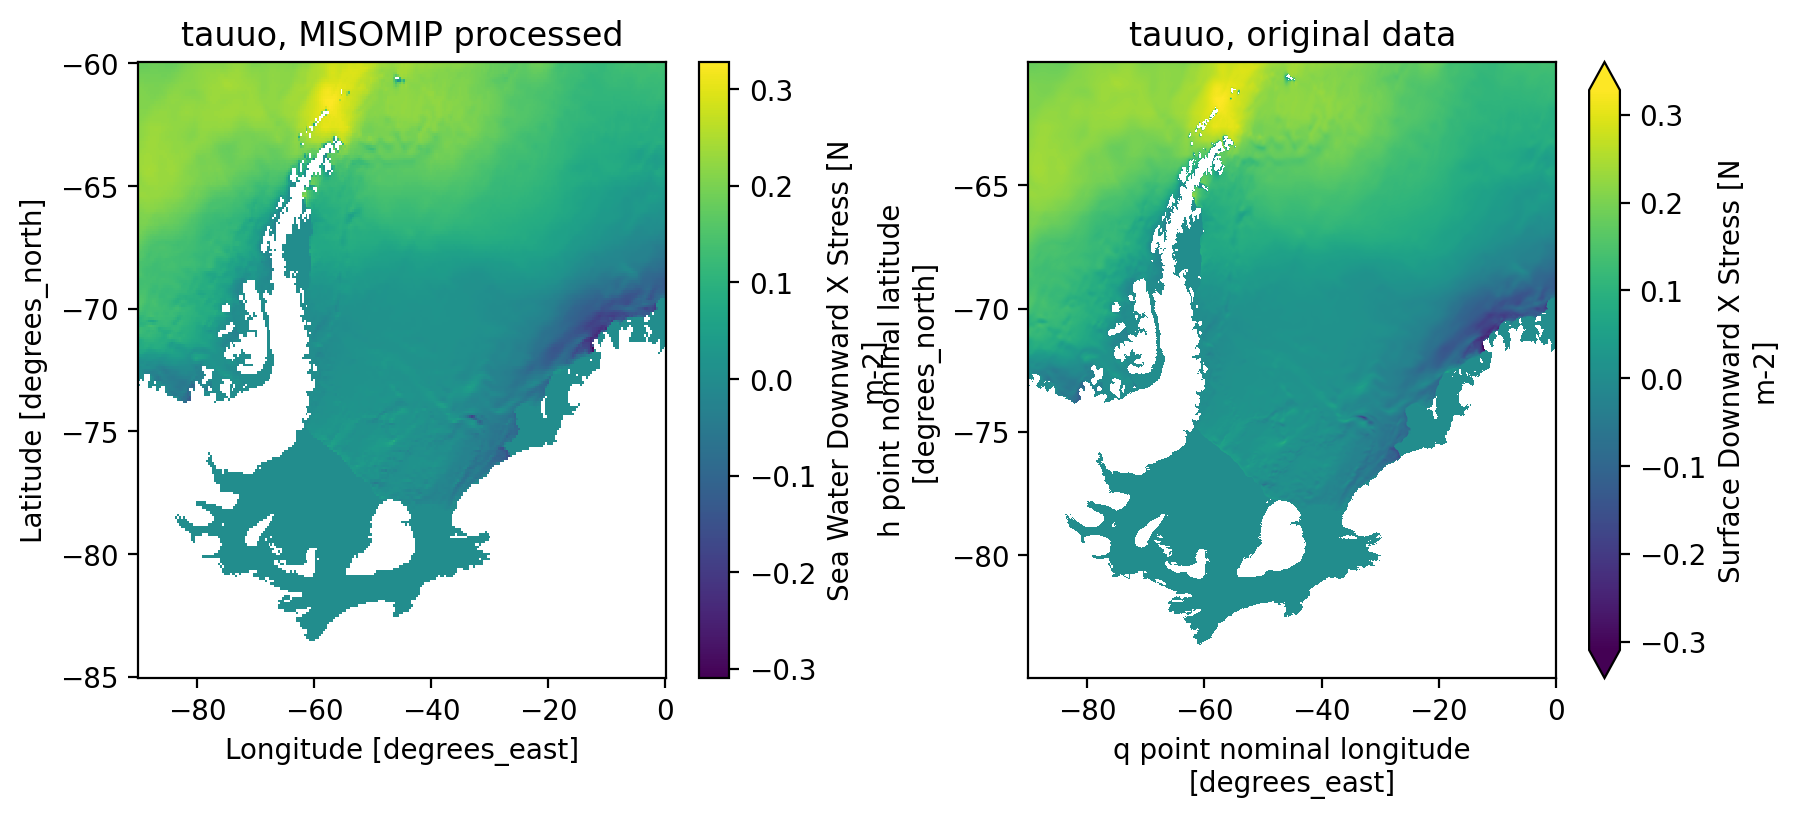

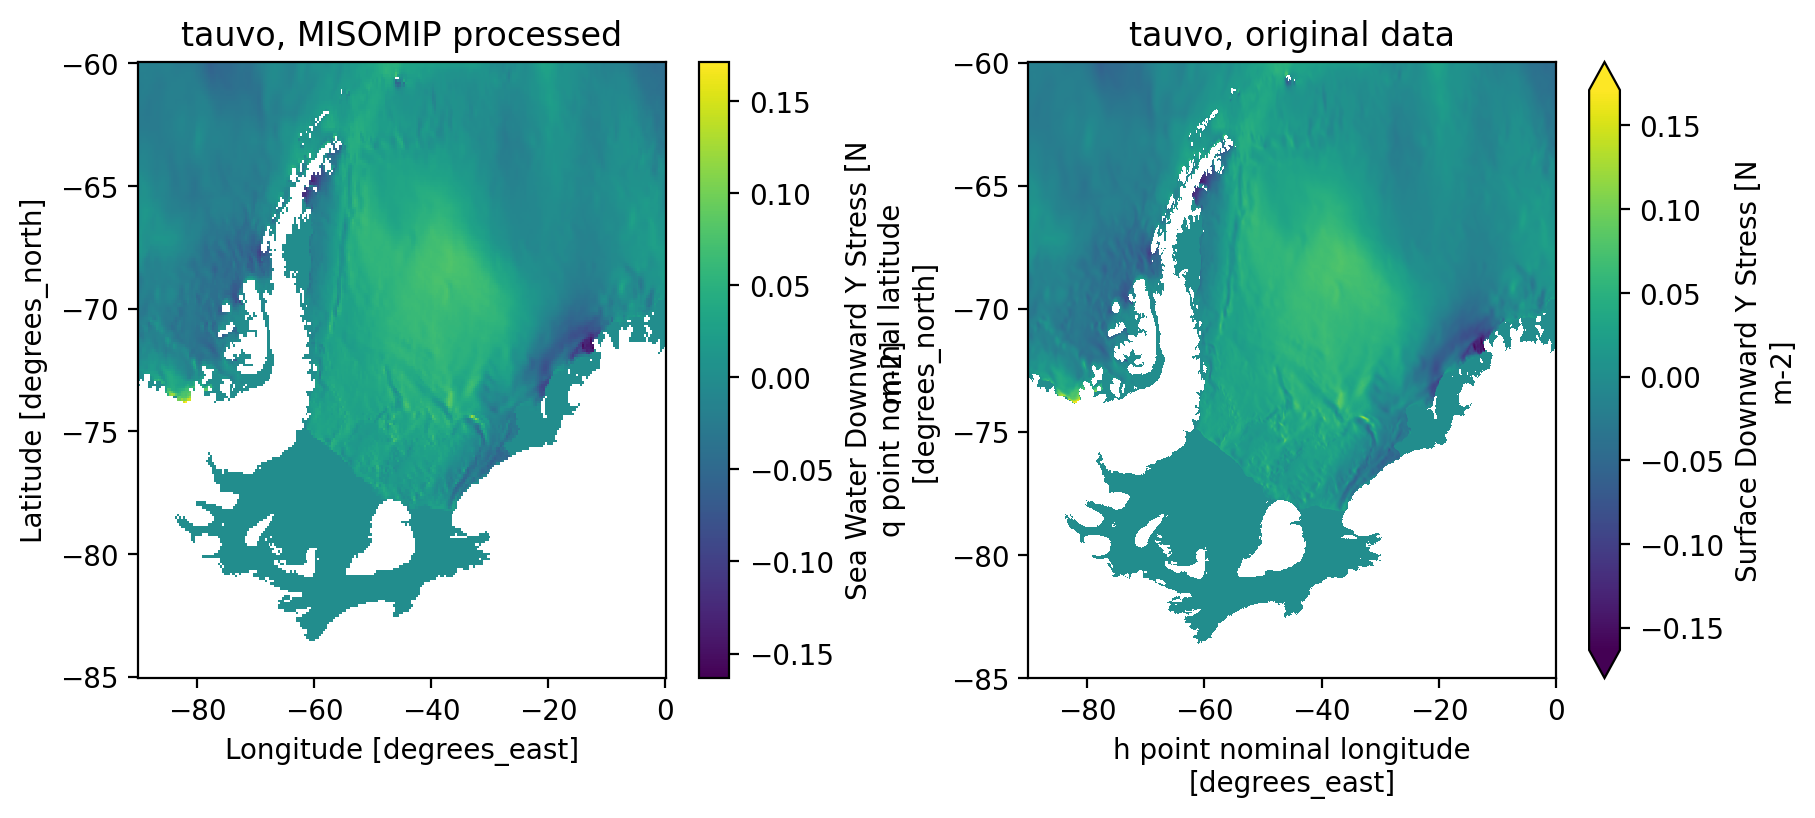

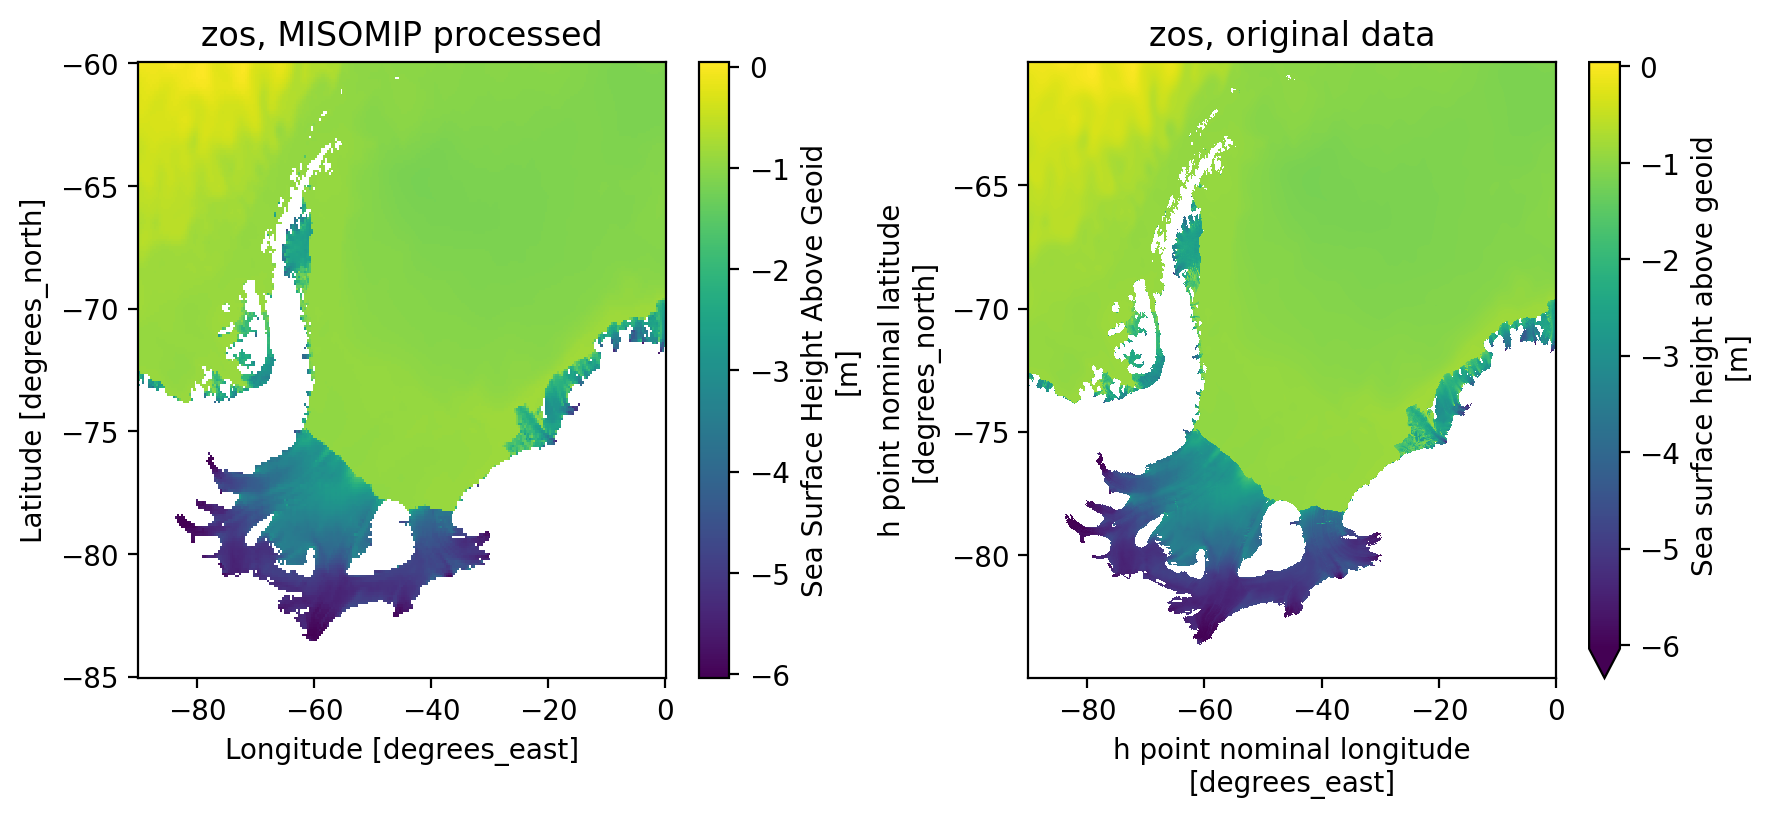

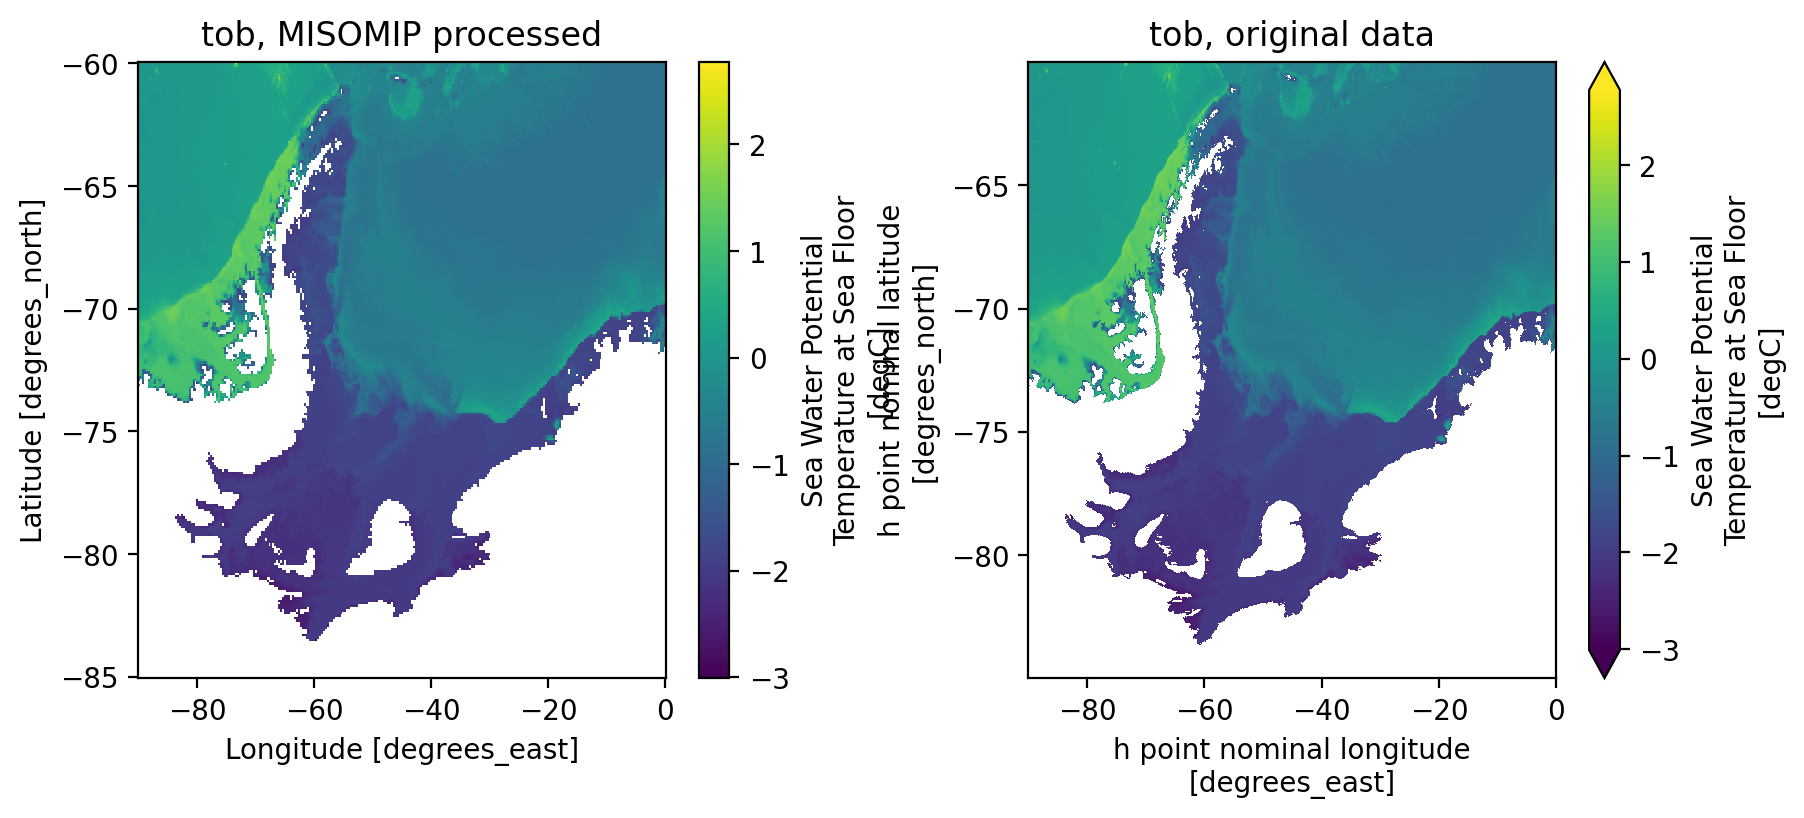

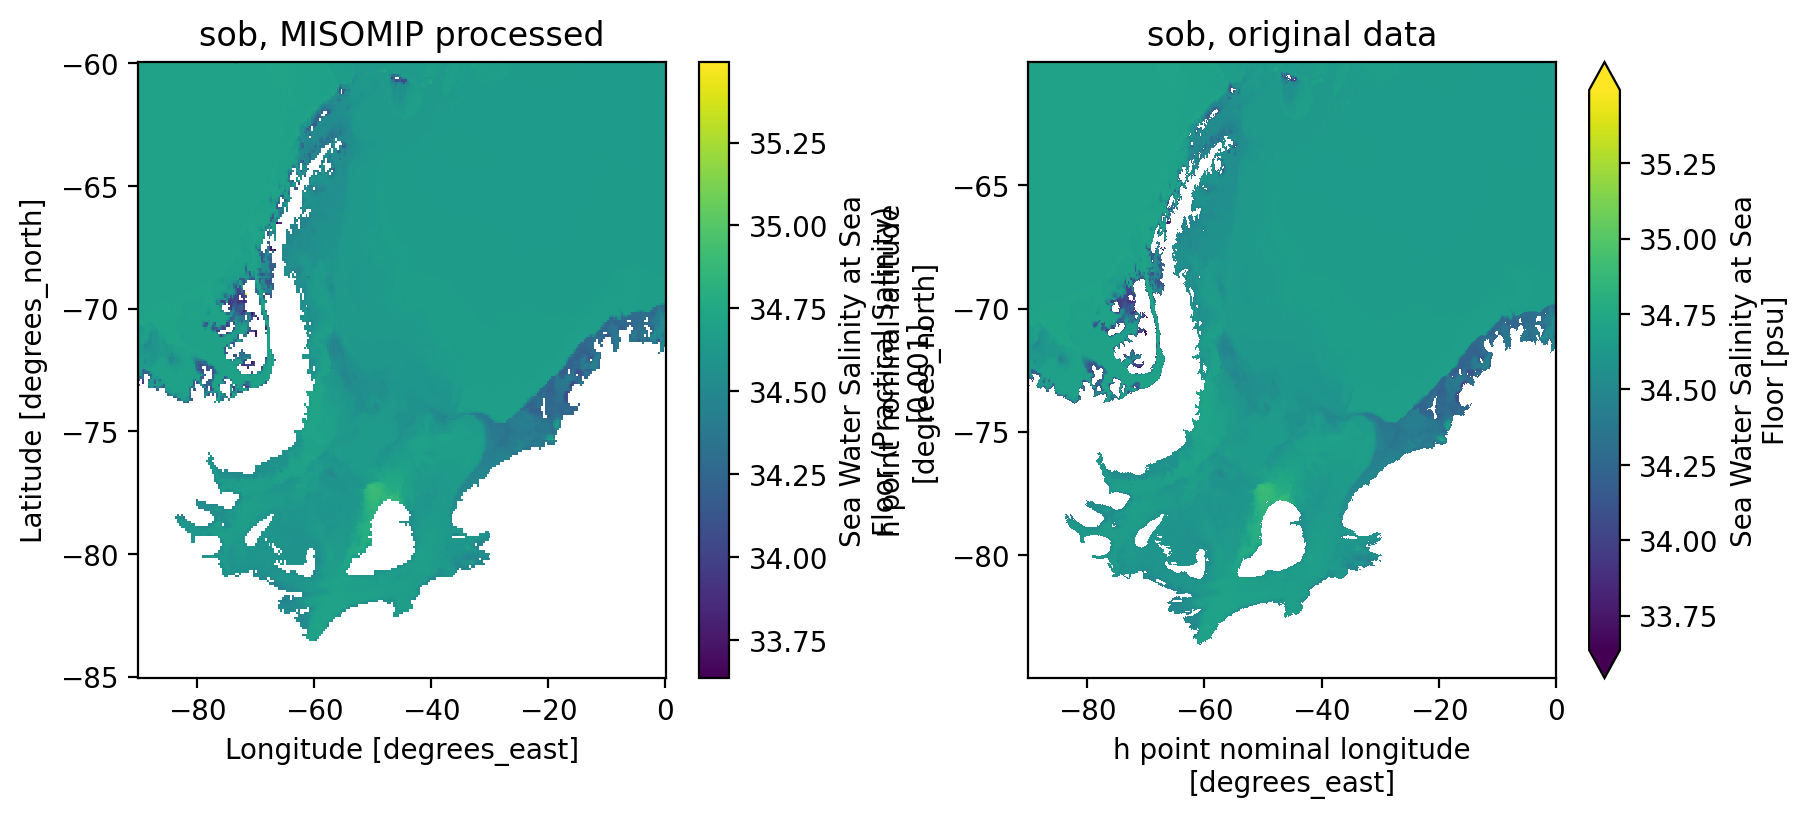

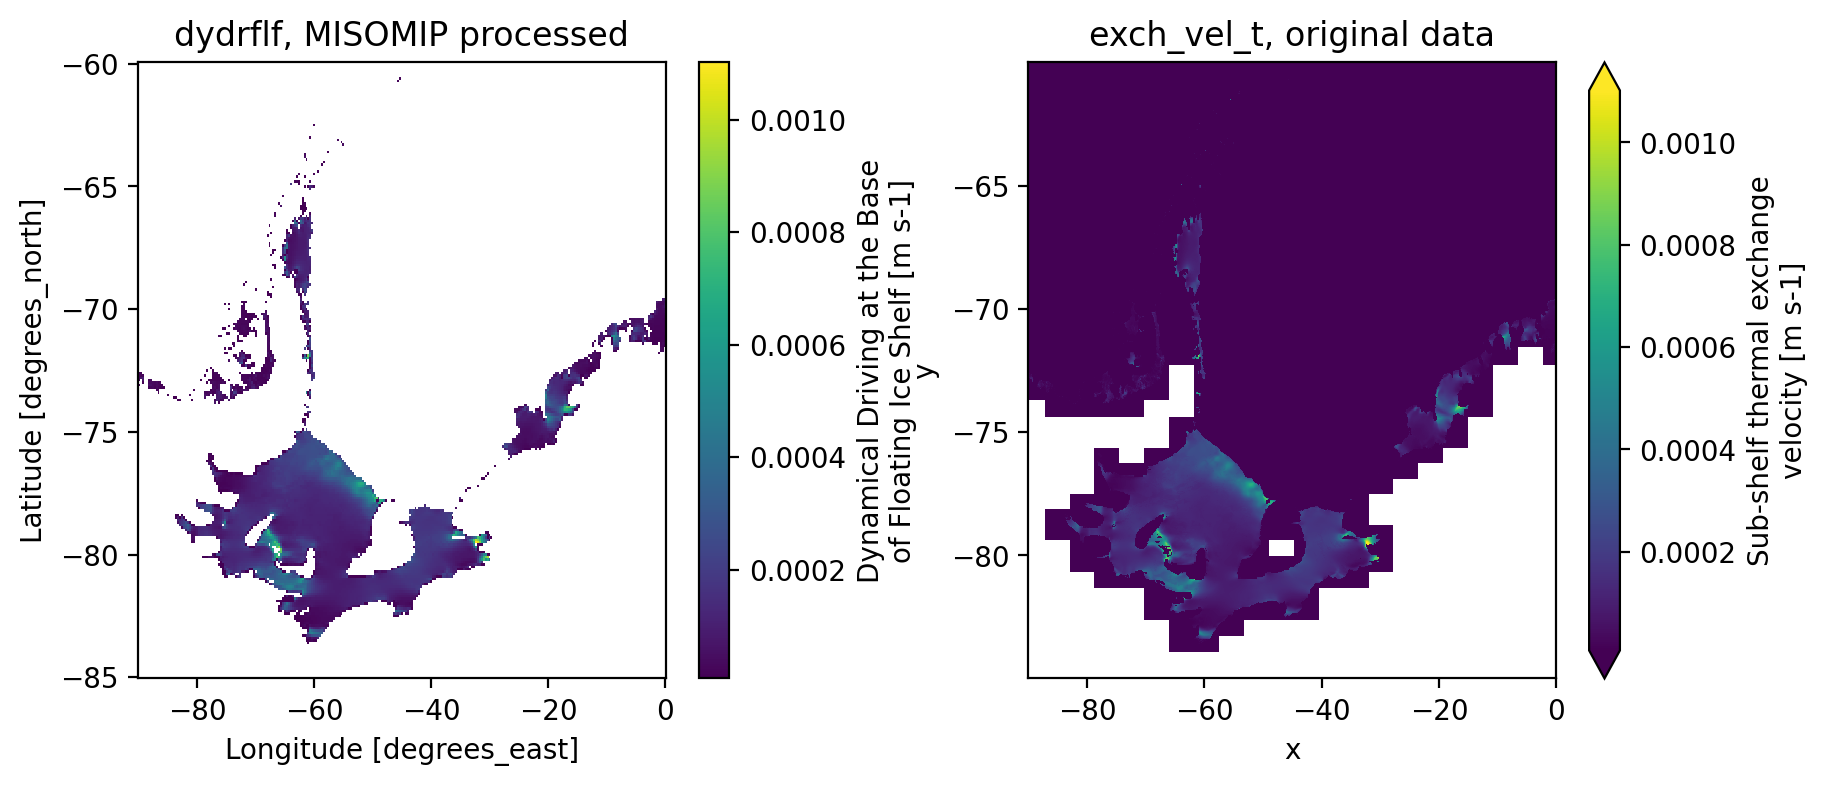

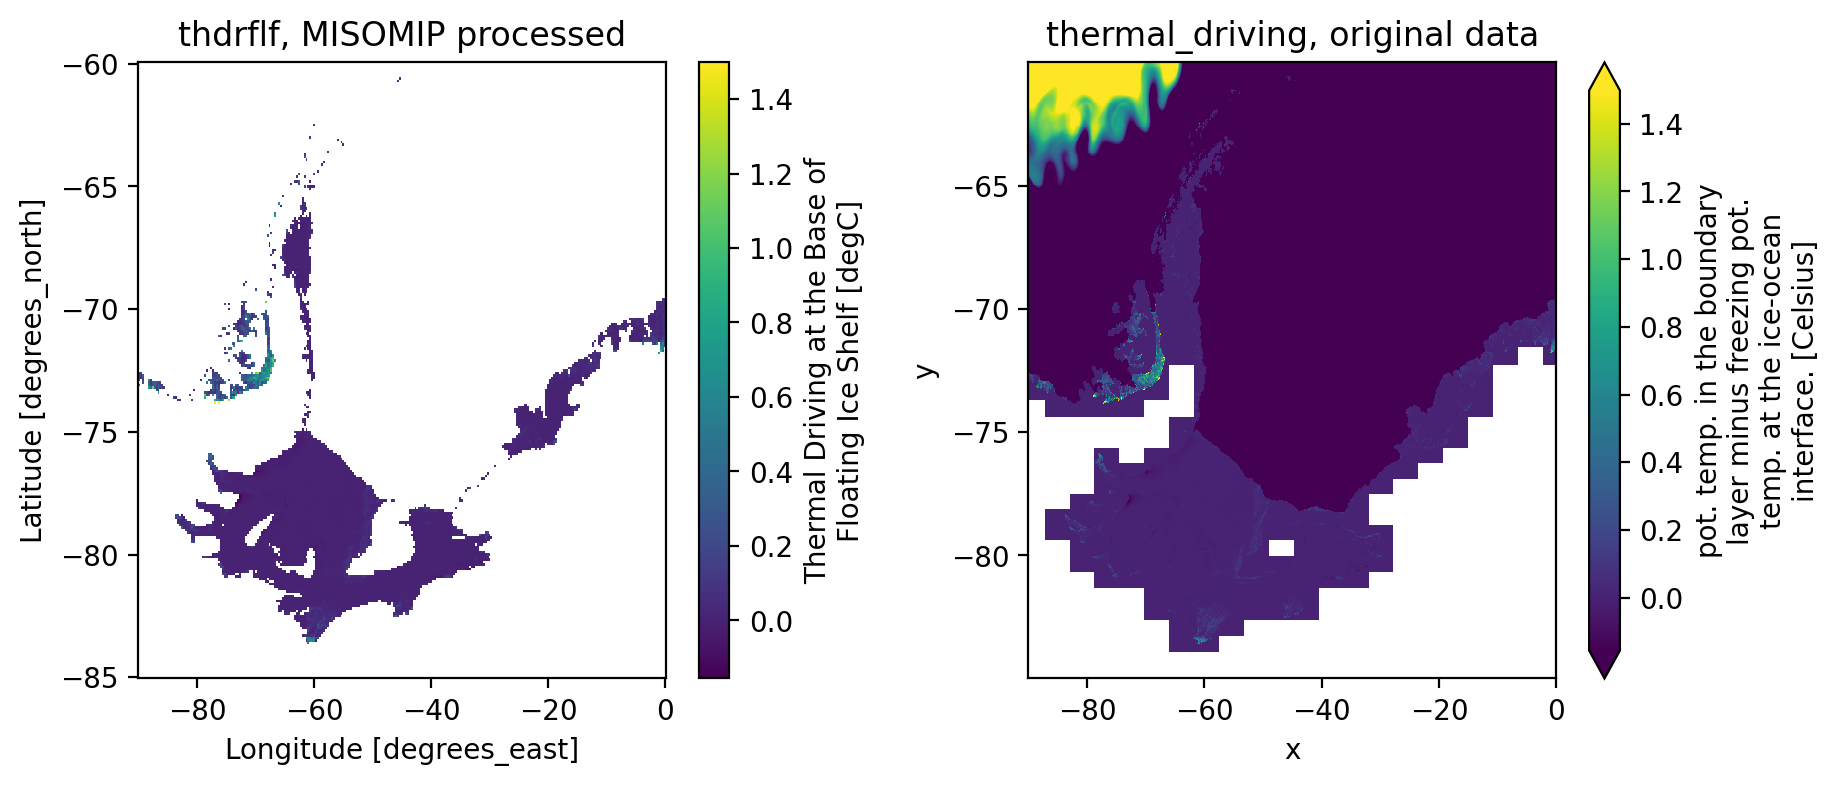

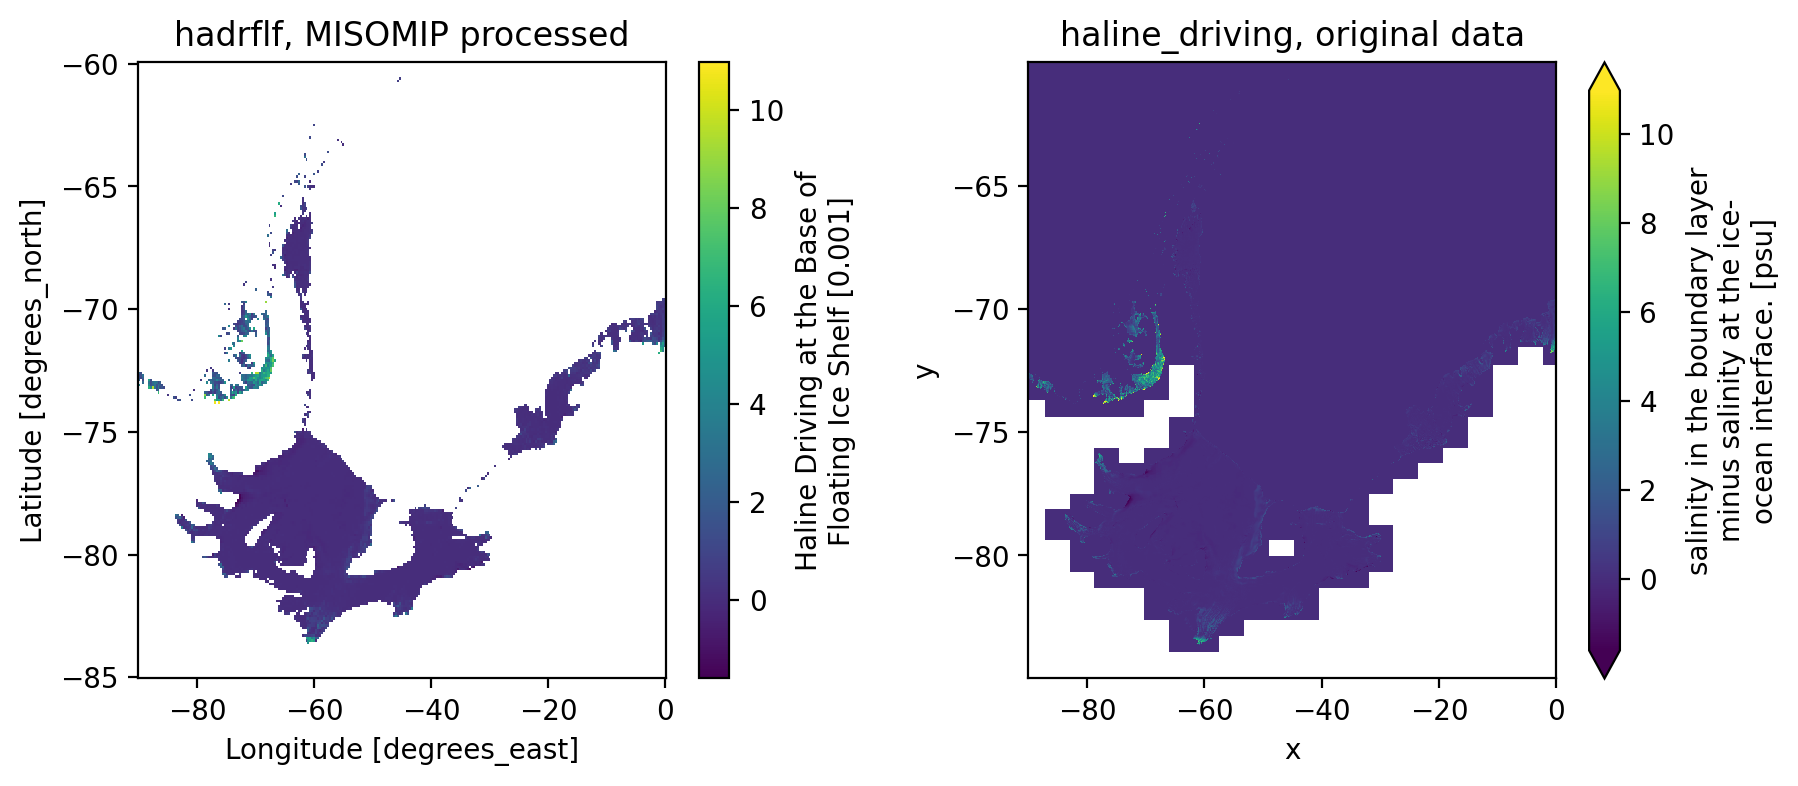

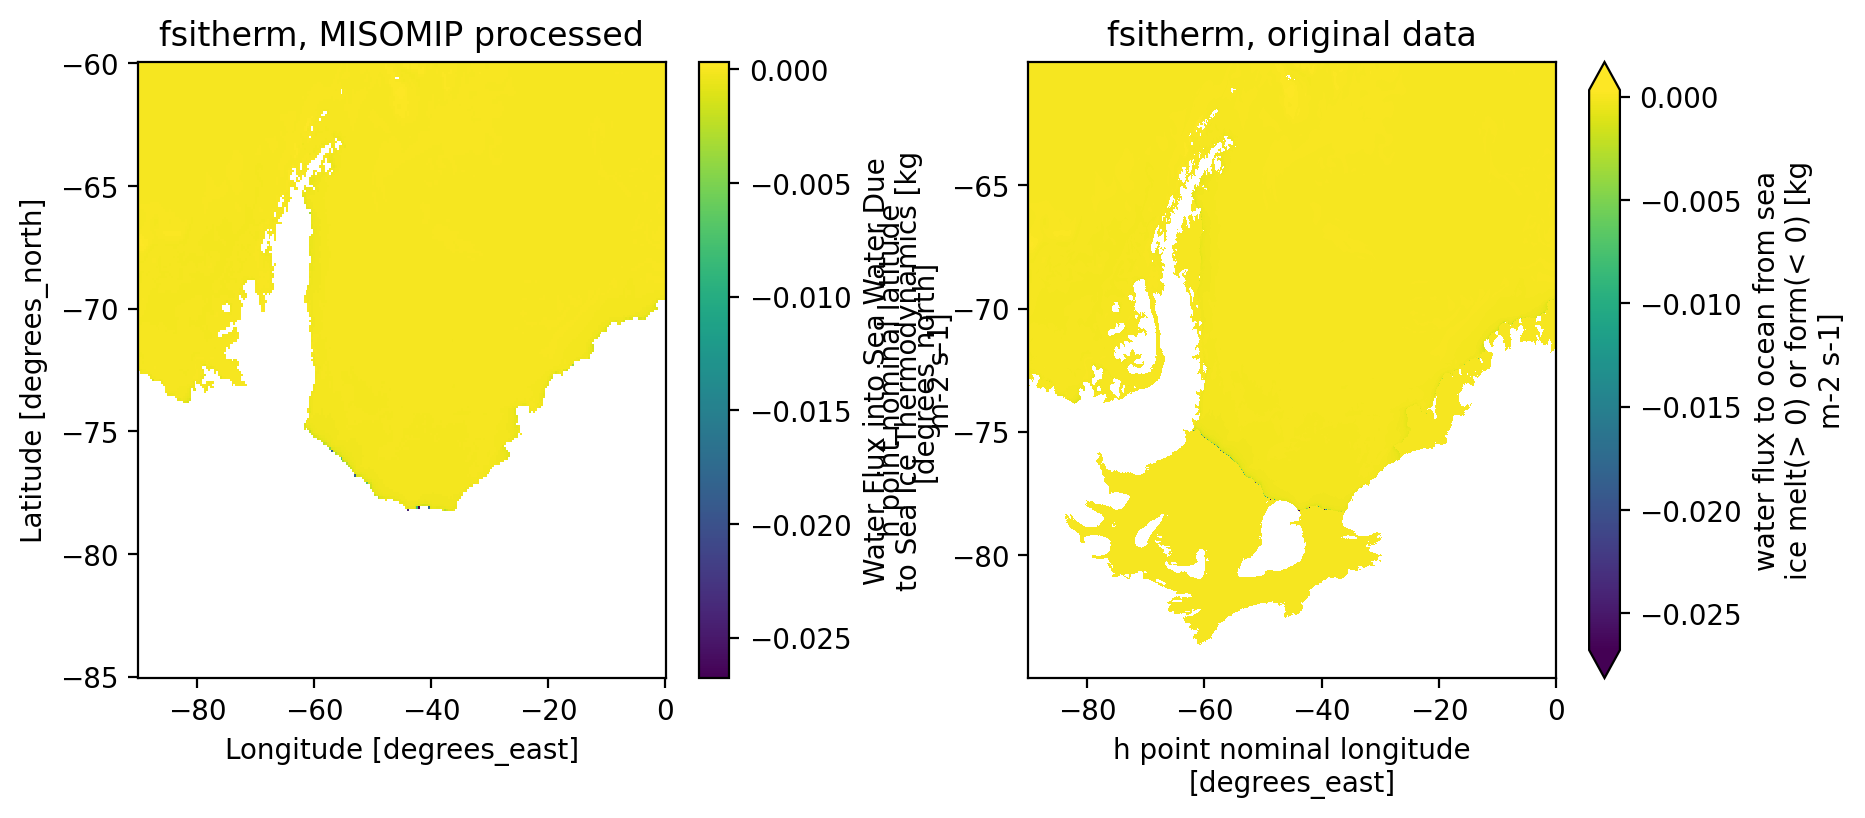

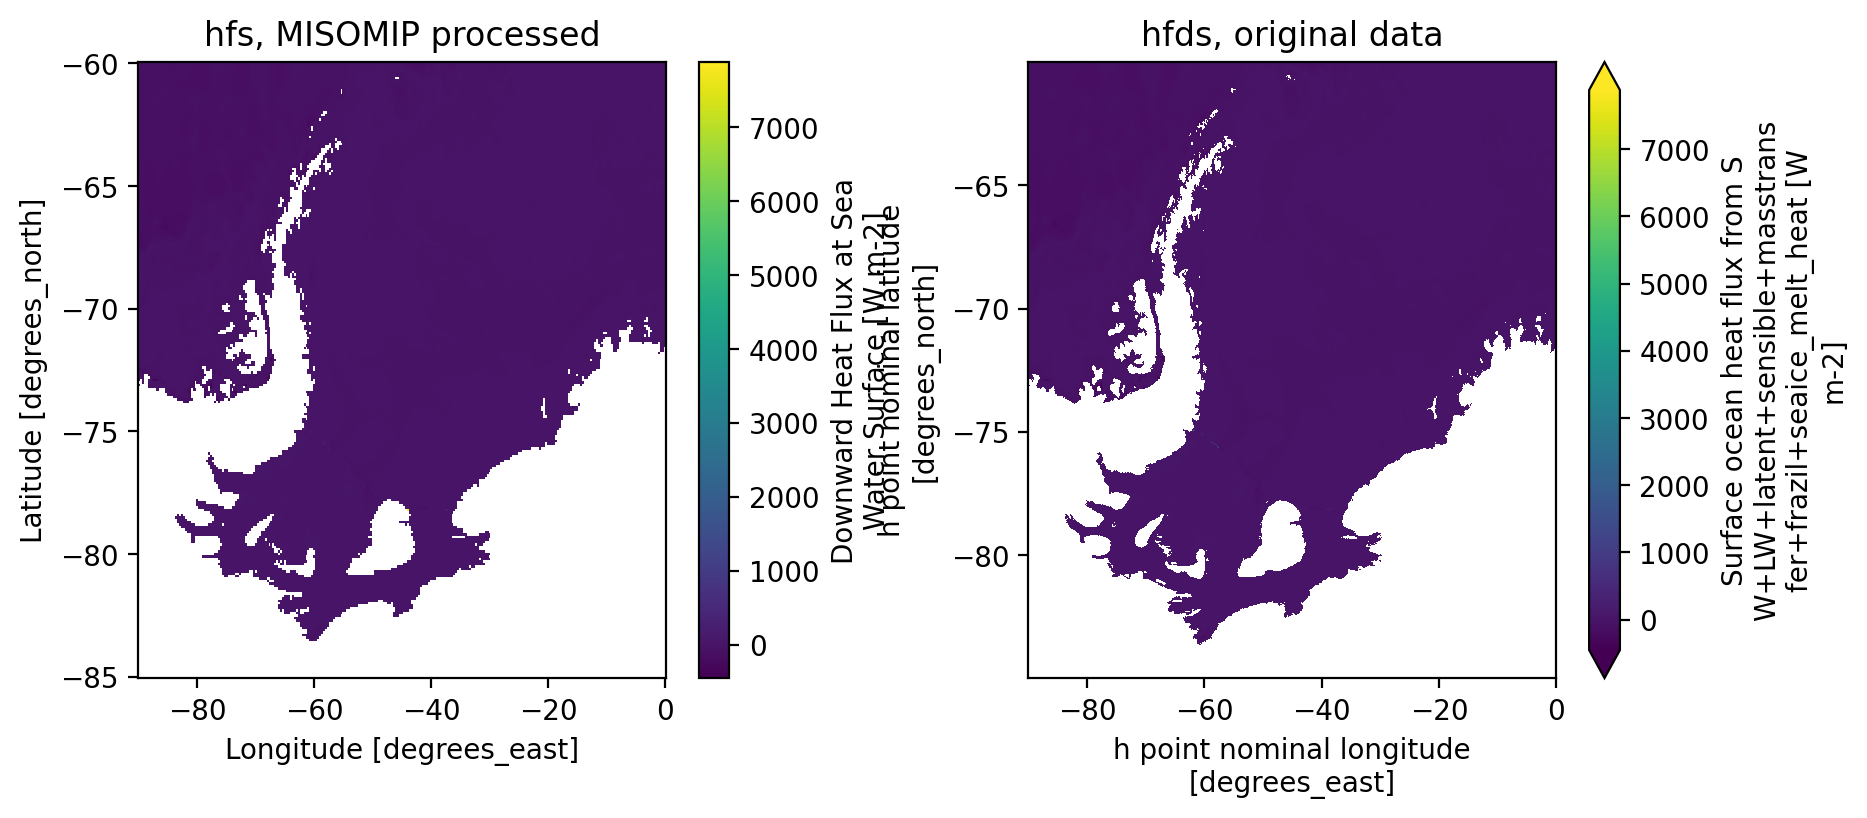

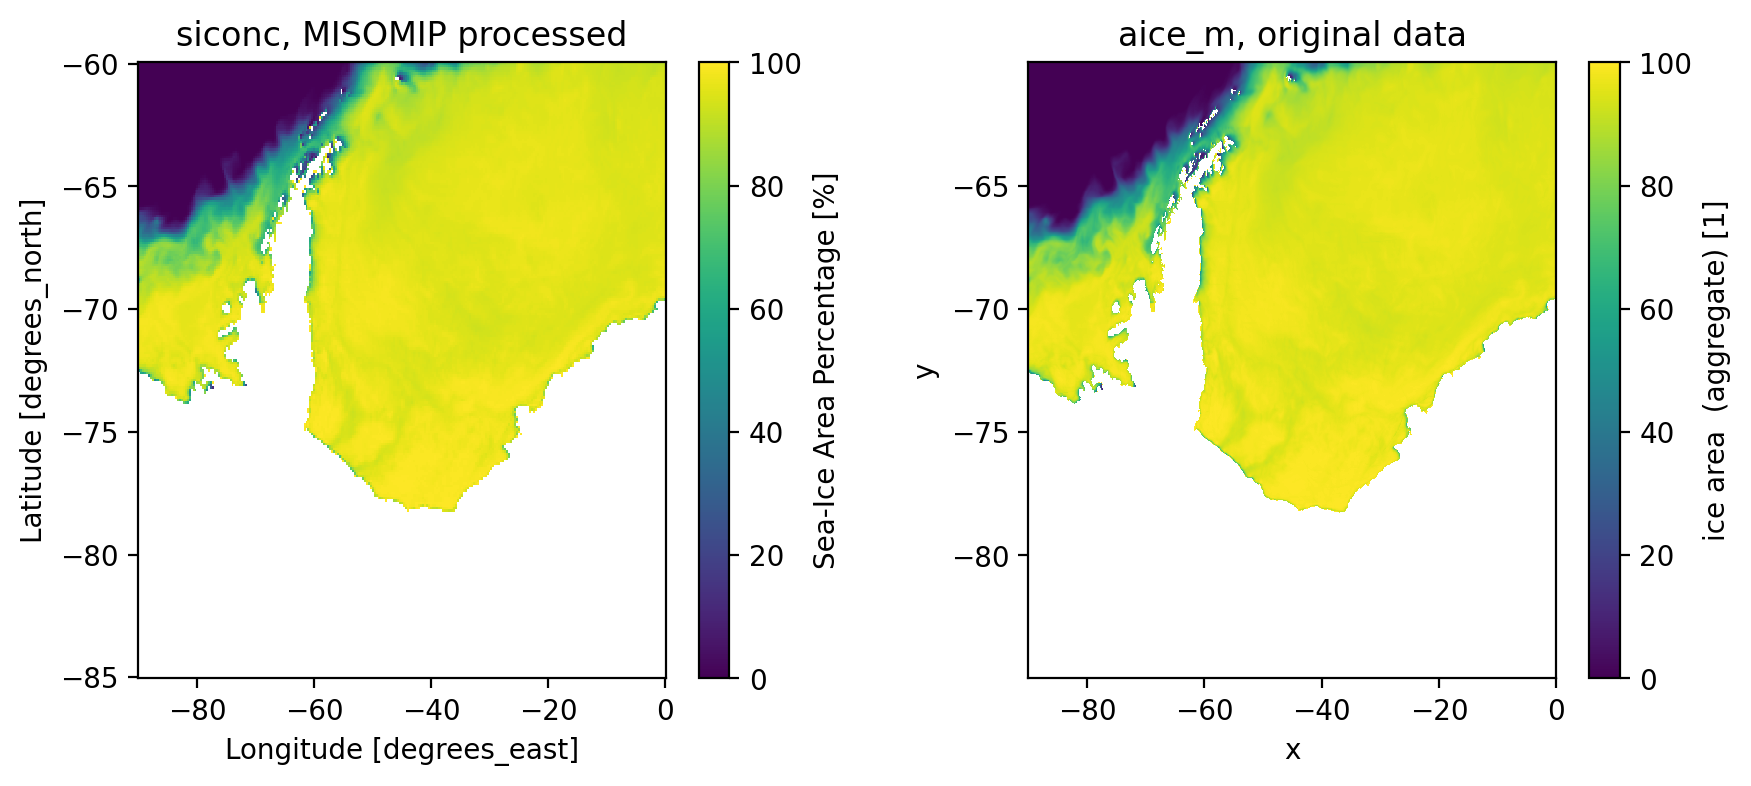

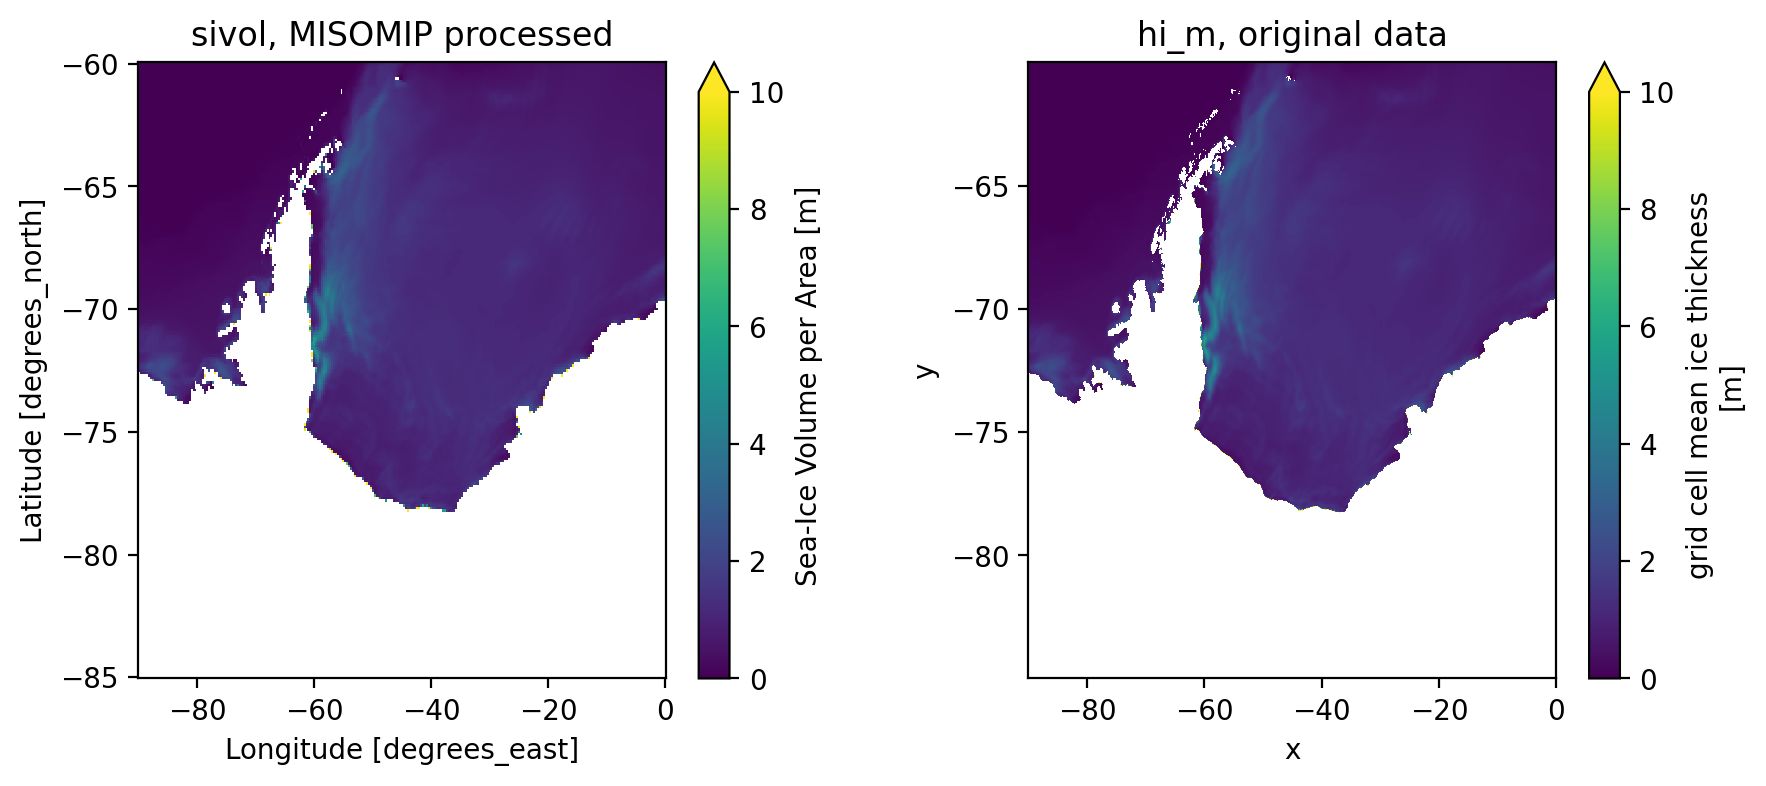

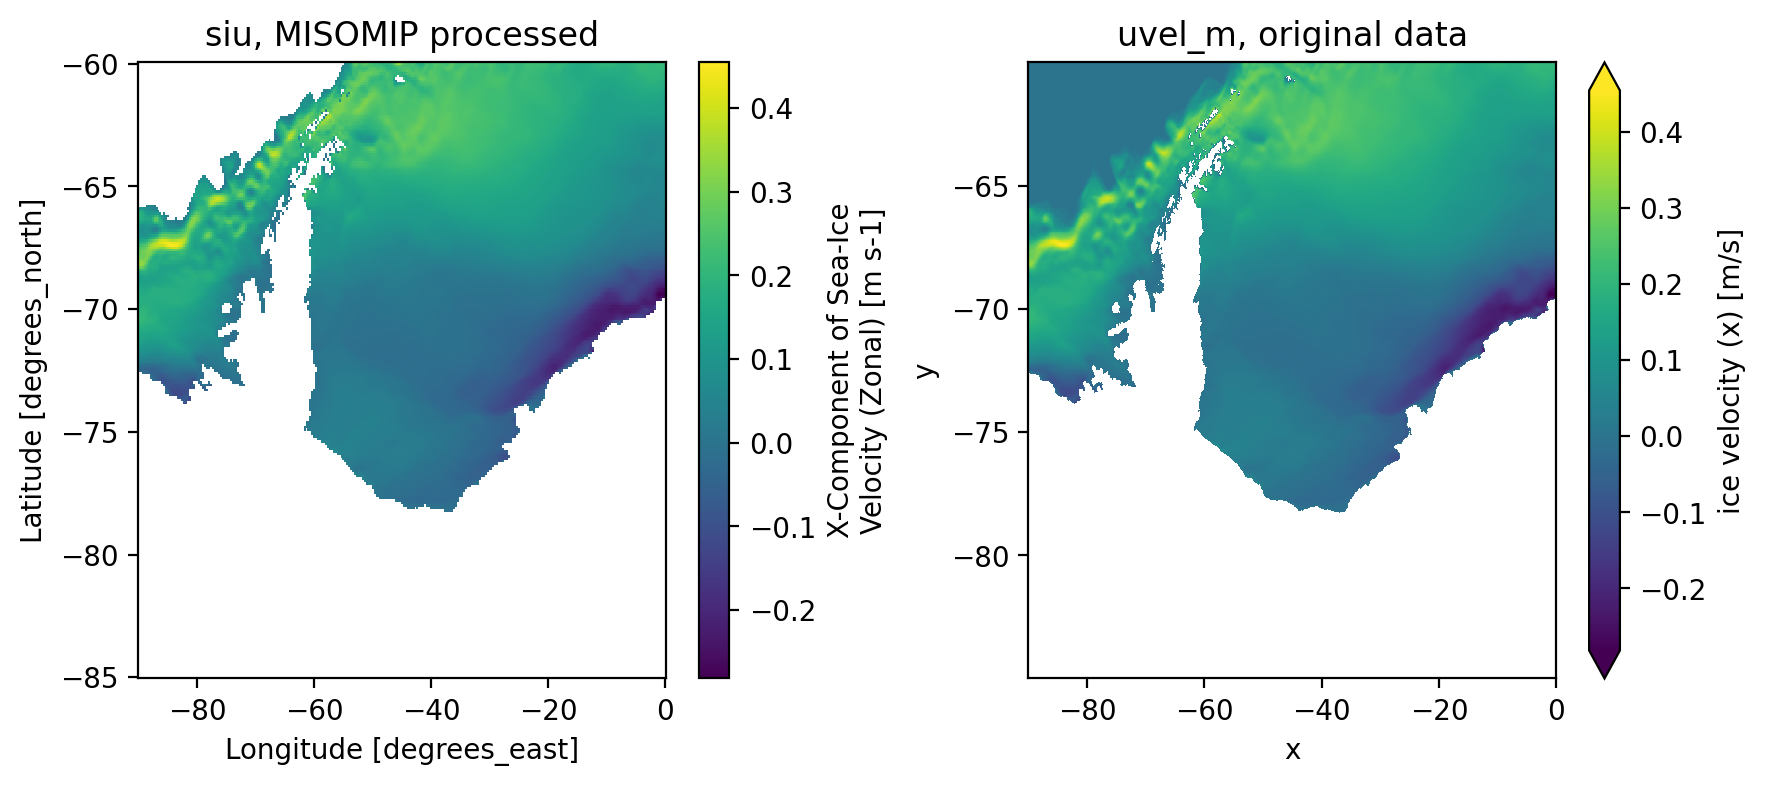

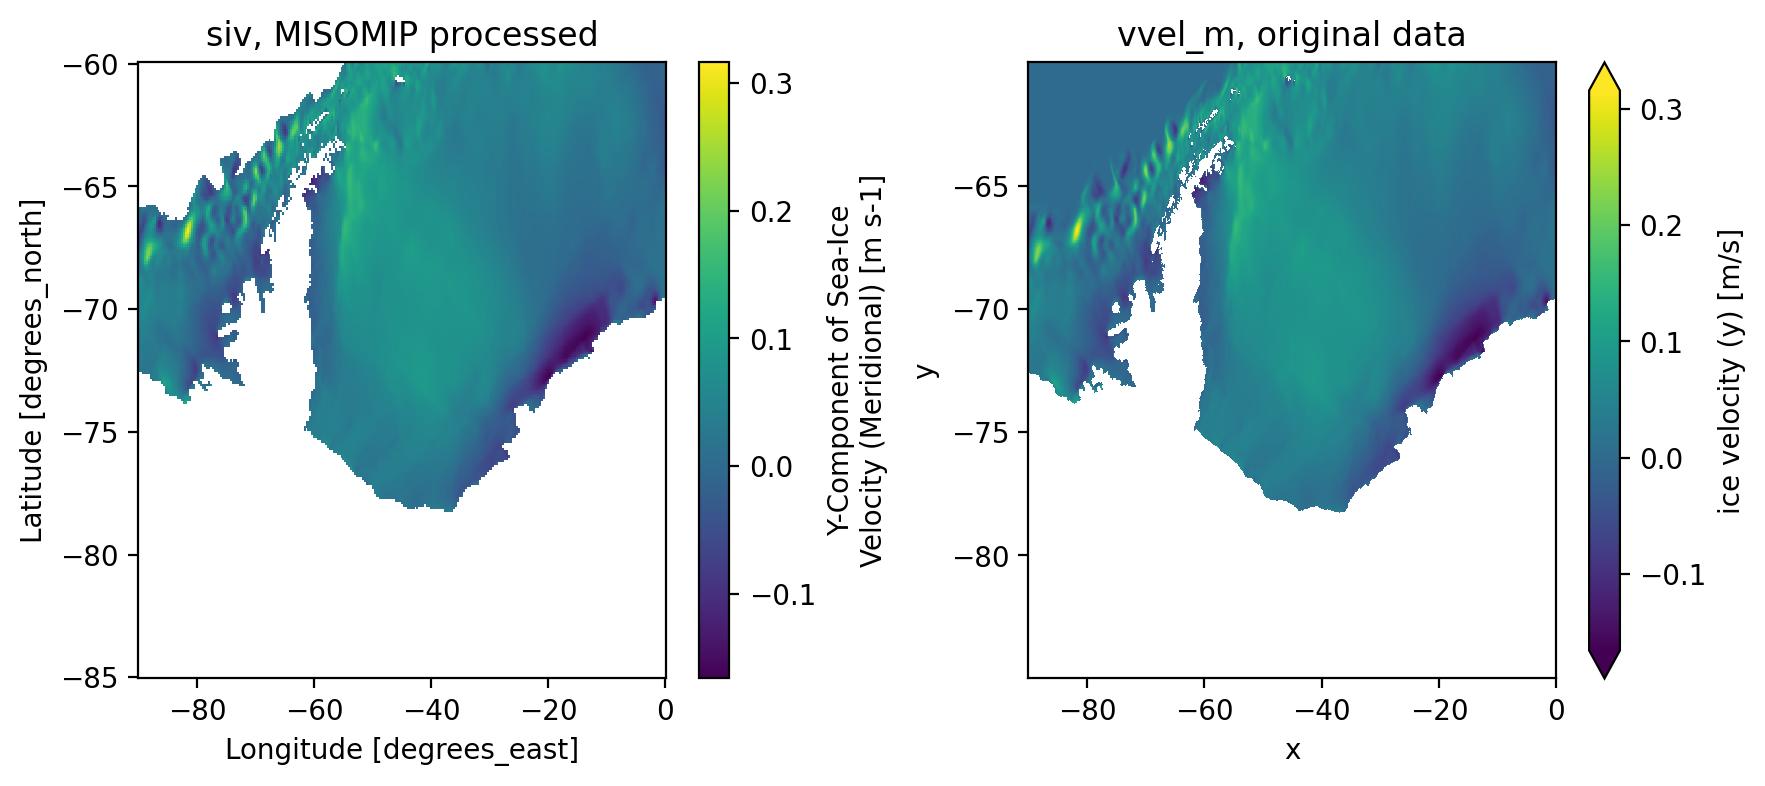

In [15]:
for ekey in var_dict.keys():
    fig, axes = plt.subplots(ncols = 2, figsize = (10,4),dpi = 200)
    var1 = ds[ekey].isel(time = 0)
    vmax = var1.max().values
    vmin = var1.min().values

    if ekey == 'sivol':
        vmax = 10
    
    var1.plot(ax = axes[0], vmax = vmax, vmin = vmin)
    axes[0].set_title(ekey+', MISOMIP processed')
    temp_ds = var_dict[ekey]['ds']
    
    var = rename_dimensions(temp_ds[var_dict[ekey]['mom_var']]).isel(time = 0)
    if ekey in ['dydrflf','thdrflf','hadrflf','siconc','sivol','siu','siv']:
        var['x'] = ncT.xh.values
        var['y'] = ncT.yh.values
    # elif ekey == 'siu':
    #     var['x'] = 

    if ekey == 'siconc':
        var = var * 100
    
    var = var.sel(x = lon_range, y = lat_range)
    var.plot(ax = axes[1], vmax = vmax, vmin = vmin)
    axes[1].set_title(var_dict[ekey]['mom_var']+', original data')
    fig.subplots_adjust(wspace = 0.35)
    plt.show()

# check more complicated 2D vars

1.4107276e-05
1.5195222066807369e-05


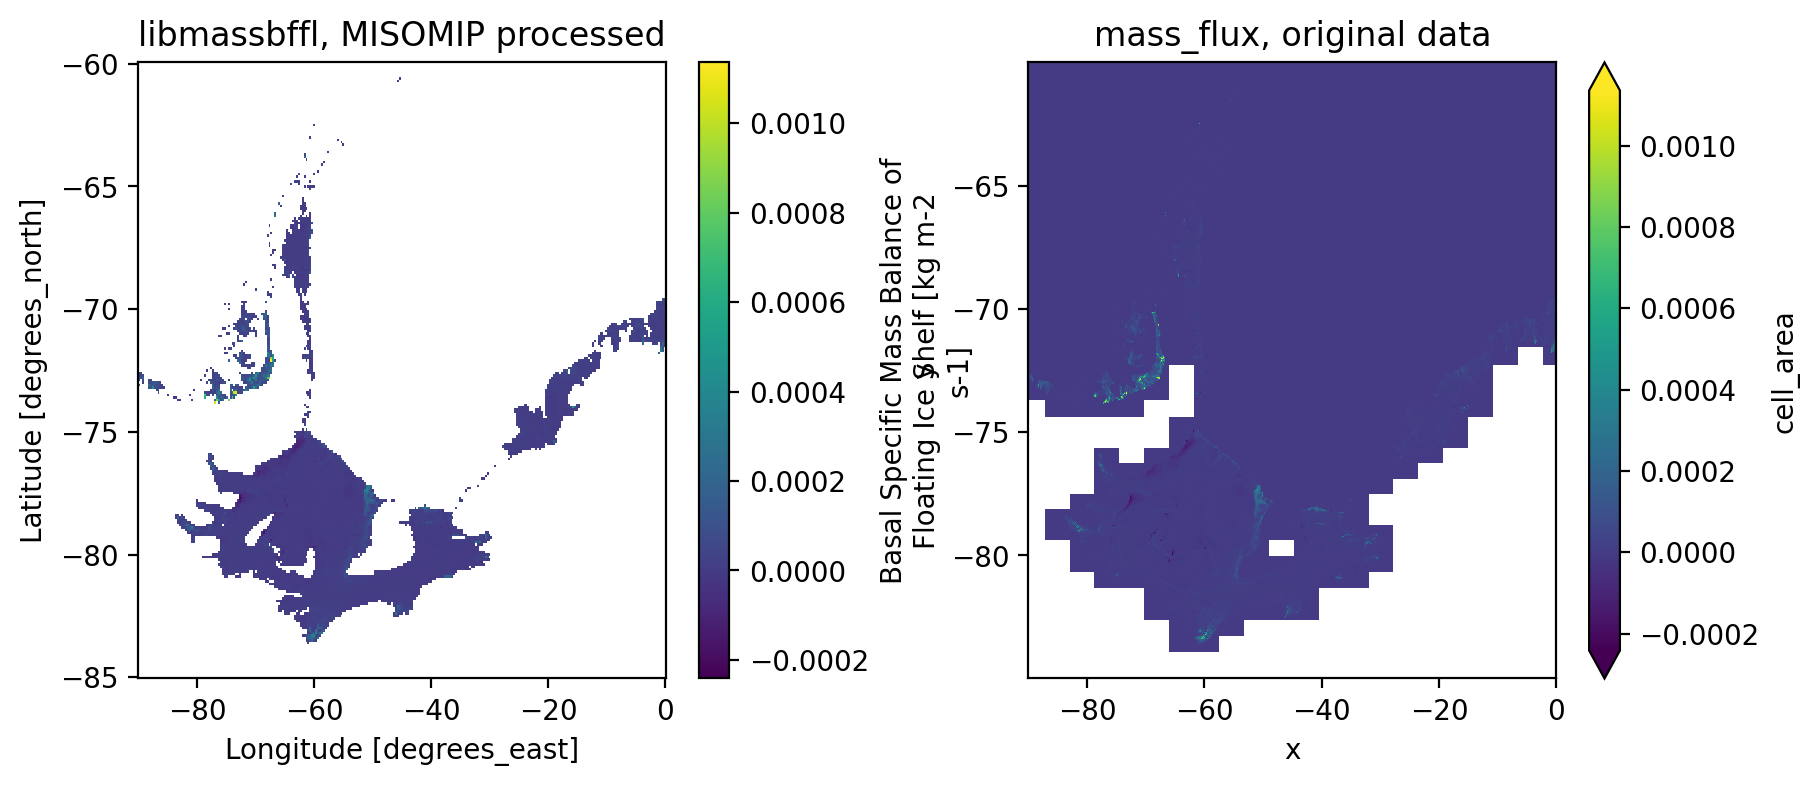

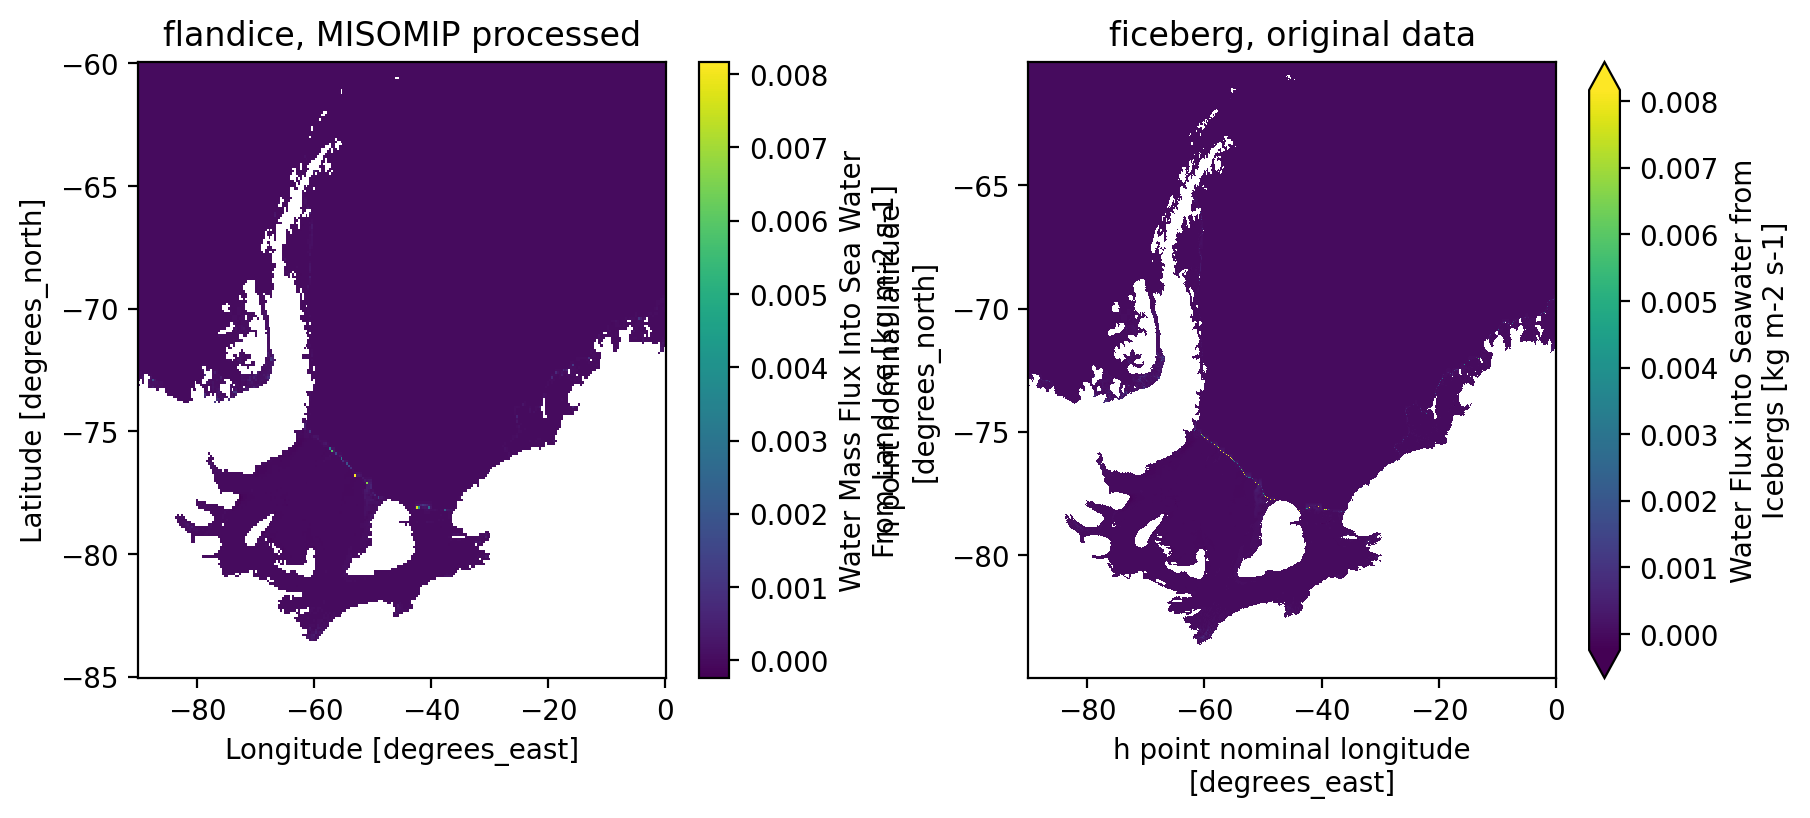

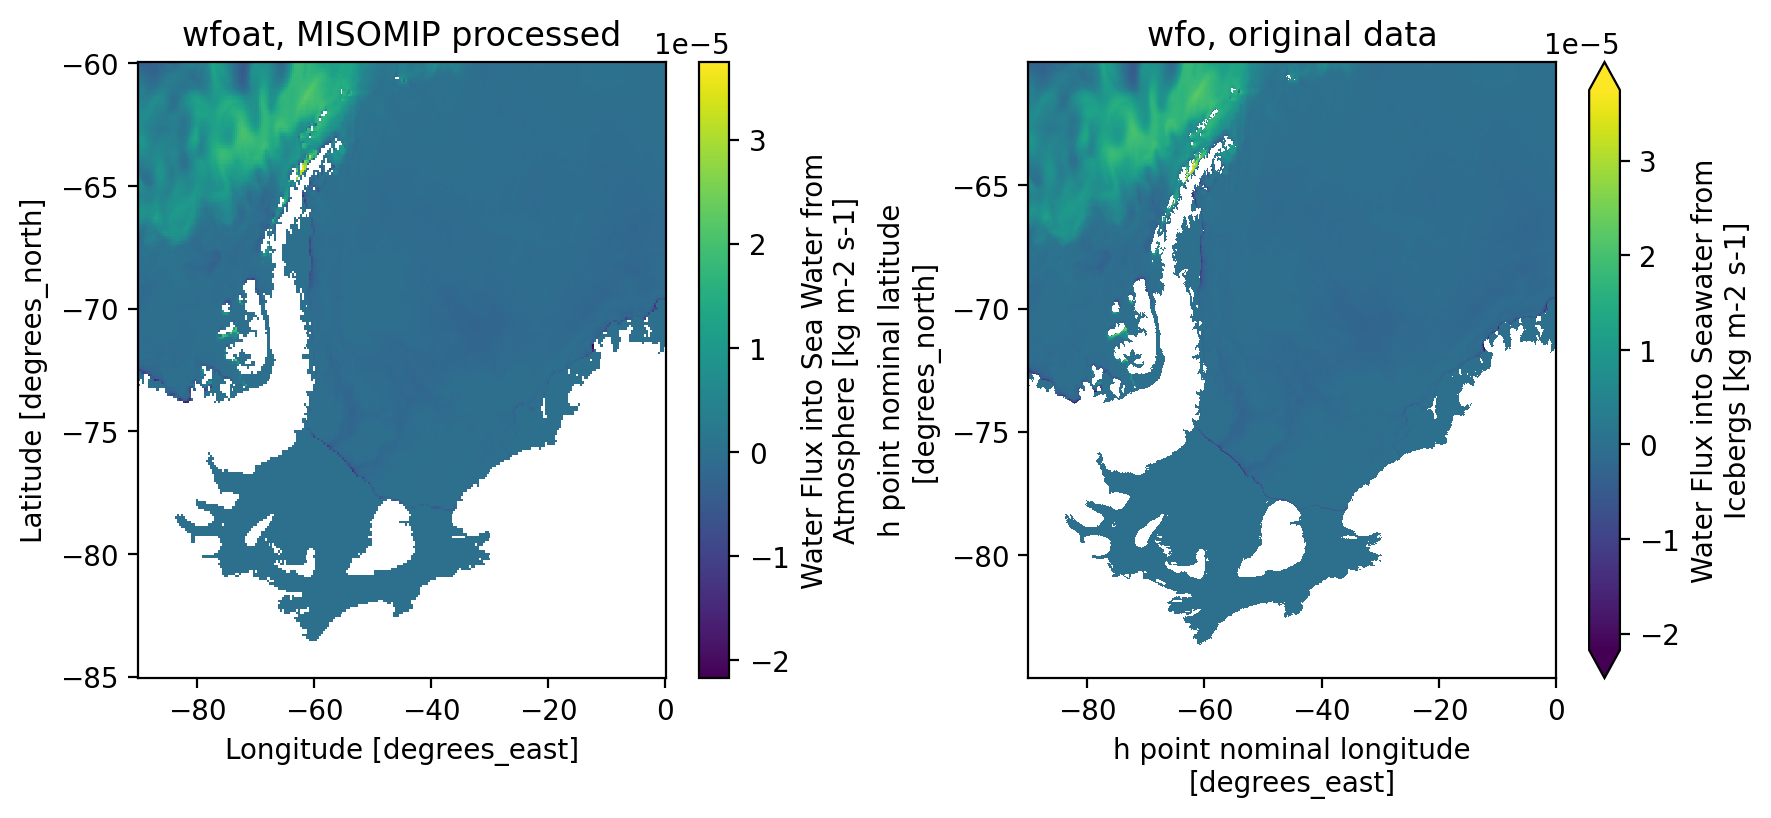

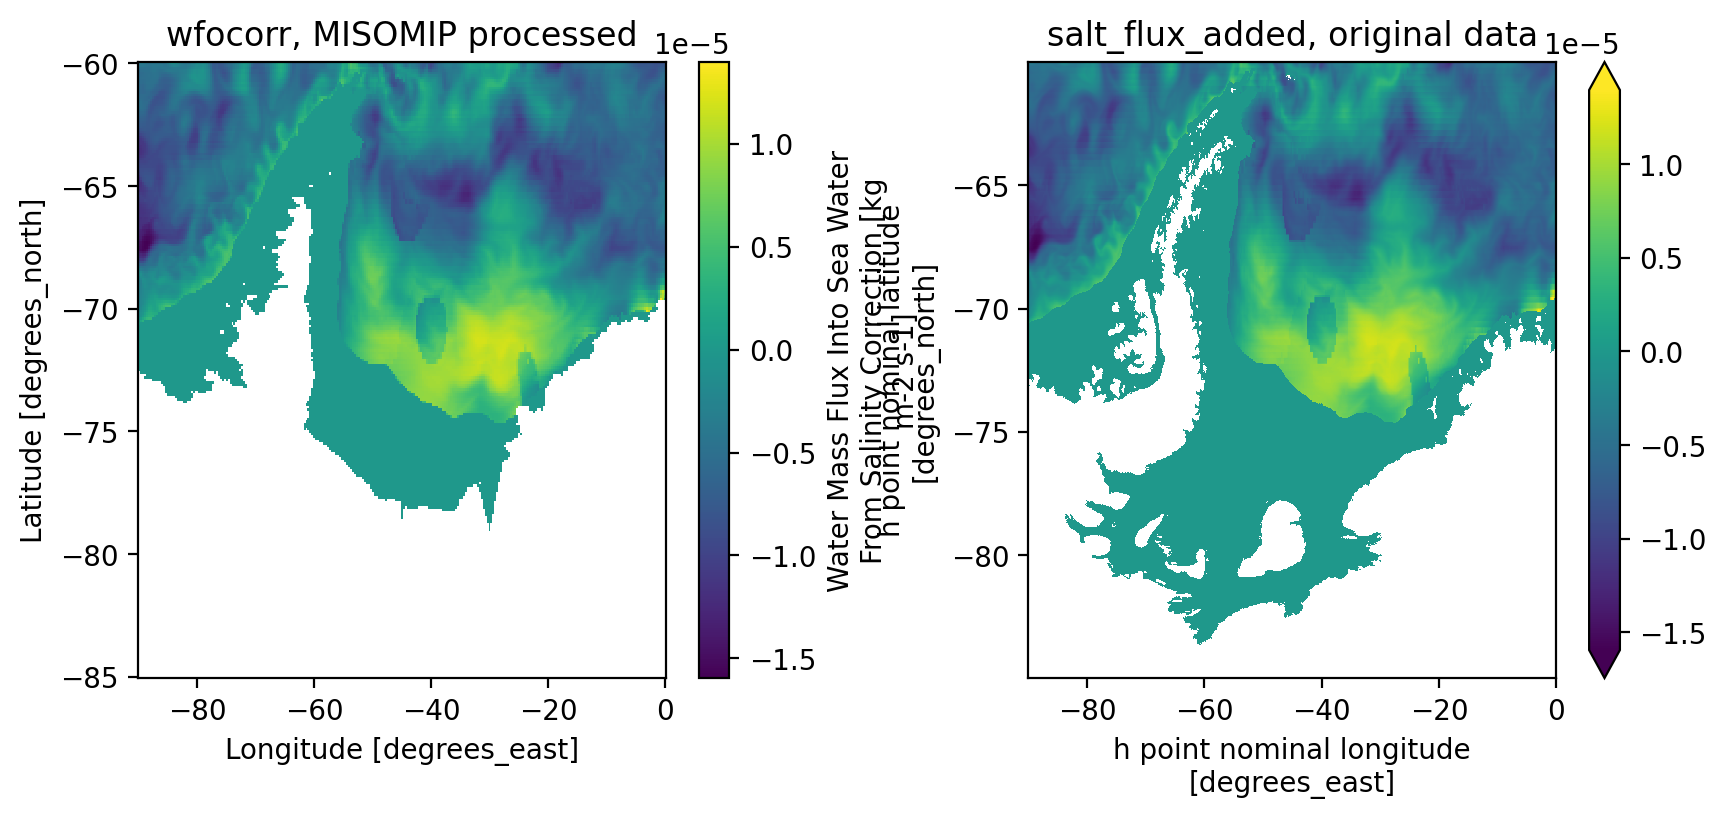

In [18]:
var_dict = {'libmassbffl':{'ds': ncS, 'mom_var':  'mass_flux'},
#            'msftbarot':{'ds': , 'mom_var':  },
            'flandice':{'ds': ncS, 'mom_var':  'ficeberg'},
            'wfoat':{'ds': ncS, 'mom_var': 'wfo' },
            'wfocorr':{'ds': ncS, 'mom_var': 'salt_flux_added' },
            }

for ekey in var_dict.keys():
    fig, axes = plt.subplots(ncols = 2, figsize = (10,4),dpi = 200)
    var1 = ds[ekey].isel(time = 0)
    vmax = var1.max().values
    vmin = var1.min().values
    
    var1.plot(ax = axes[0], vmax = vmax, vmin = vmin)
    axes[0].set_title(ekey+', MISOMIP processed')
    temp_ds = var_dict[ekey]['ds']

    if ekey == 'libmassbffl':
        # need to divide by area
        print(var1.where(var1!=0).mean().values)
        area = rename_dimensions(ncM.areacello)
        var = rename_dimensions(temp_ds[var_dict[ekey]['mom_var']]).isel(time = 0)/area
        var['x'] = ncT.xh.values
        var['y'] = ncT.yh.values
        print(var.where(var!=0).mean().values)
    elif ekey == 'flandice':
        # need to divide by area
        area = rename_dimensions(ncM.areacello)
        var = rename_dimensions(temp_ds[var_dict[ekey]['mom_var']]).isel(time = 0)
        var = var + rename_dimensions(temp_ds['mass_flux']).isel(time = 0)/area
    elif ekey == 'wfoat':
        area = rename_dimensions(ncM.areacello)
        var = rename_dimensions(temp_ds[var_dict[ekey]['mom_var']]).isel(time = 0) - \
              rename_dimensions(ncS.fsitherm) - \
              rename_dimensions(temp_ds[var_dict['flandice']['mom_var']]).isel(time = 0) - \
              rename_dimensions(temp_ds['mass_flux']).isel(time = 0)/area
    elif ekey == 'wfocorr':
        var = -1*rename_dimensions(temp_ds[var_dict[ekey]['mom_var']]).isel(time = 0)/ \
              rename_dimensions(ncT.salt).isel(z = 0, time = 0) * 1000
    else:
        print('bad variable')
    
    var = var.sel(x = lon_range, y = lat_range)
    var.plot(ax = axes[1], vmax = vmax, vmin = vmin)
    axes[1].set_title(var_dict[ekey]['mom_var']+', original data')
    fig.subplots_adjust(wspace = 0.35)
    plt.show()

Weird blob in salt restoring is from the file that salt is restored to...

# Check 3D sections

In [19]:
import xgcm

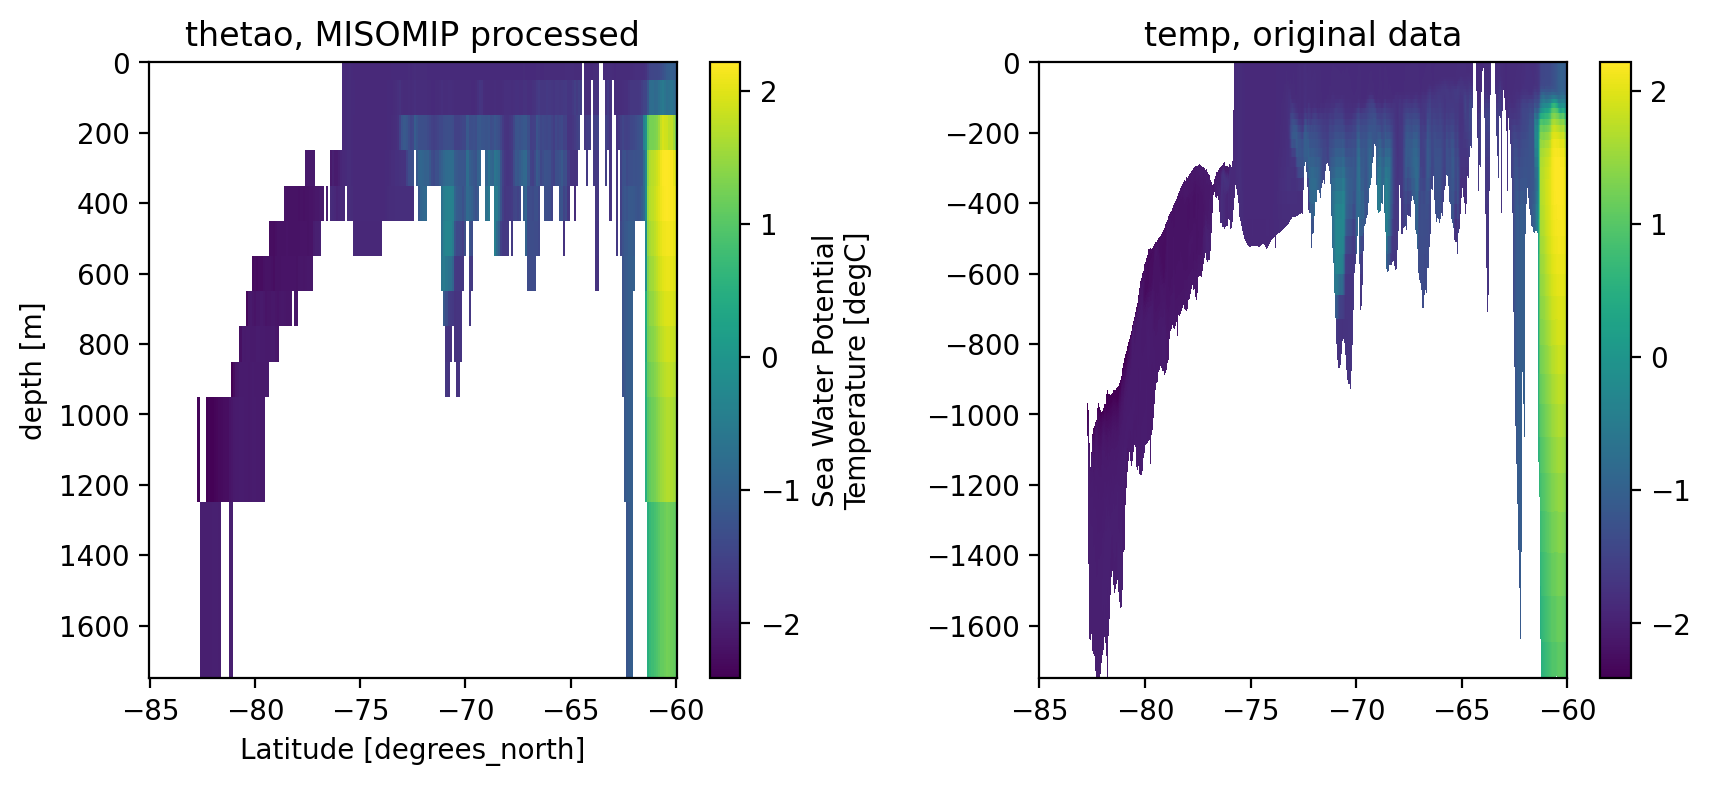

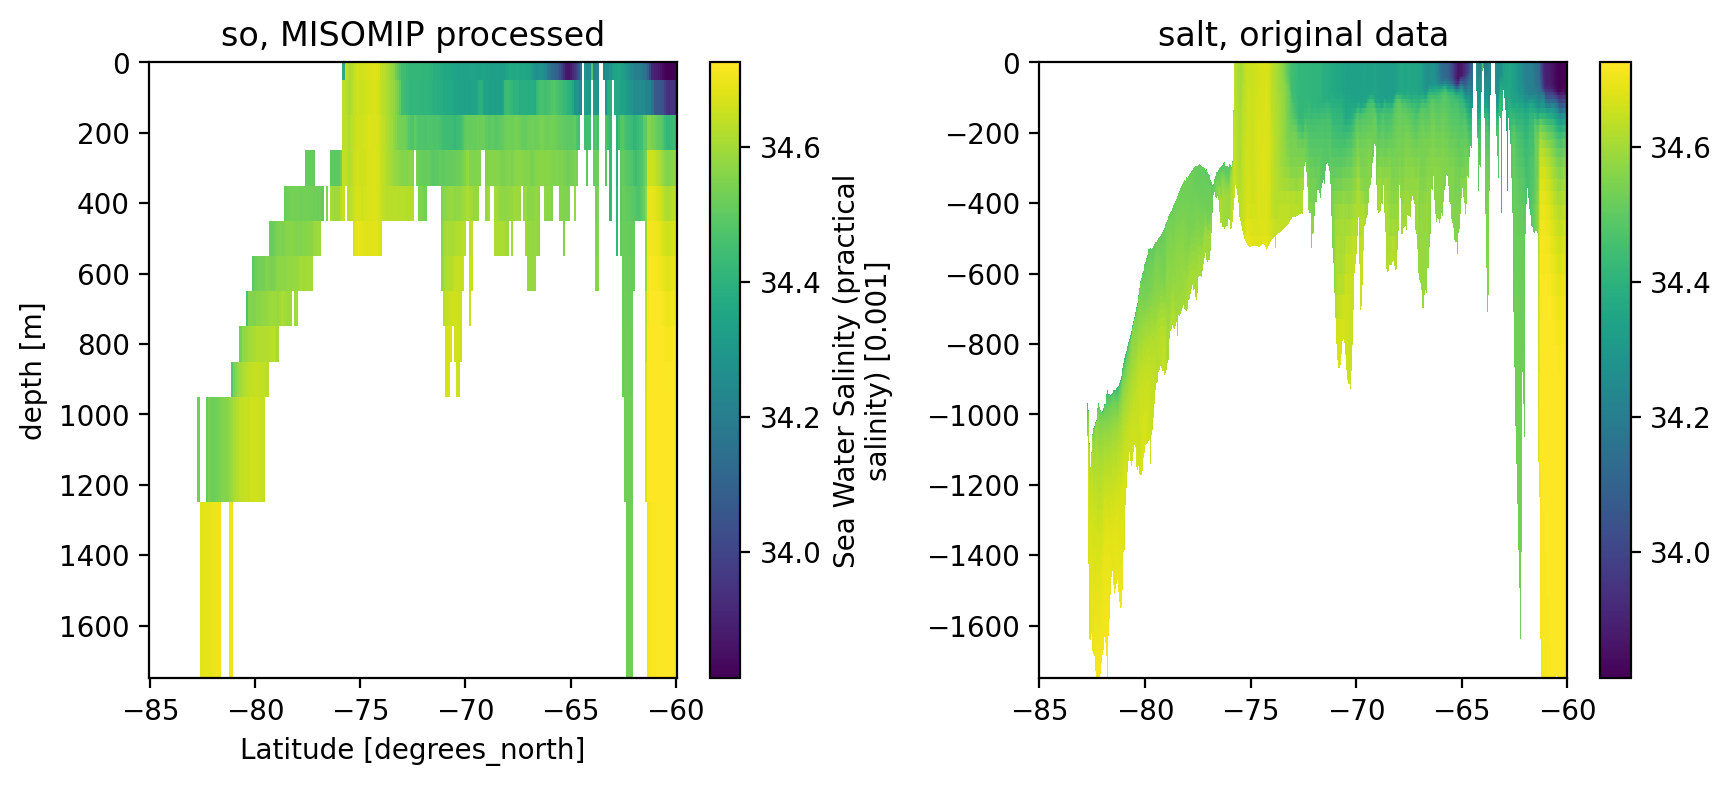

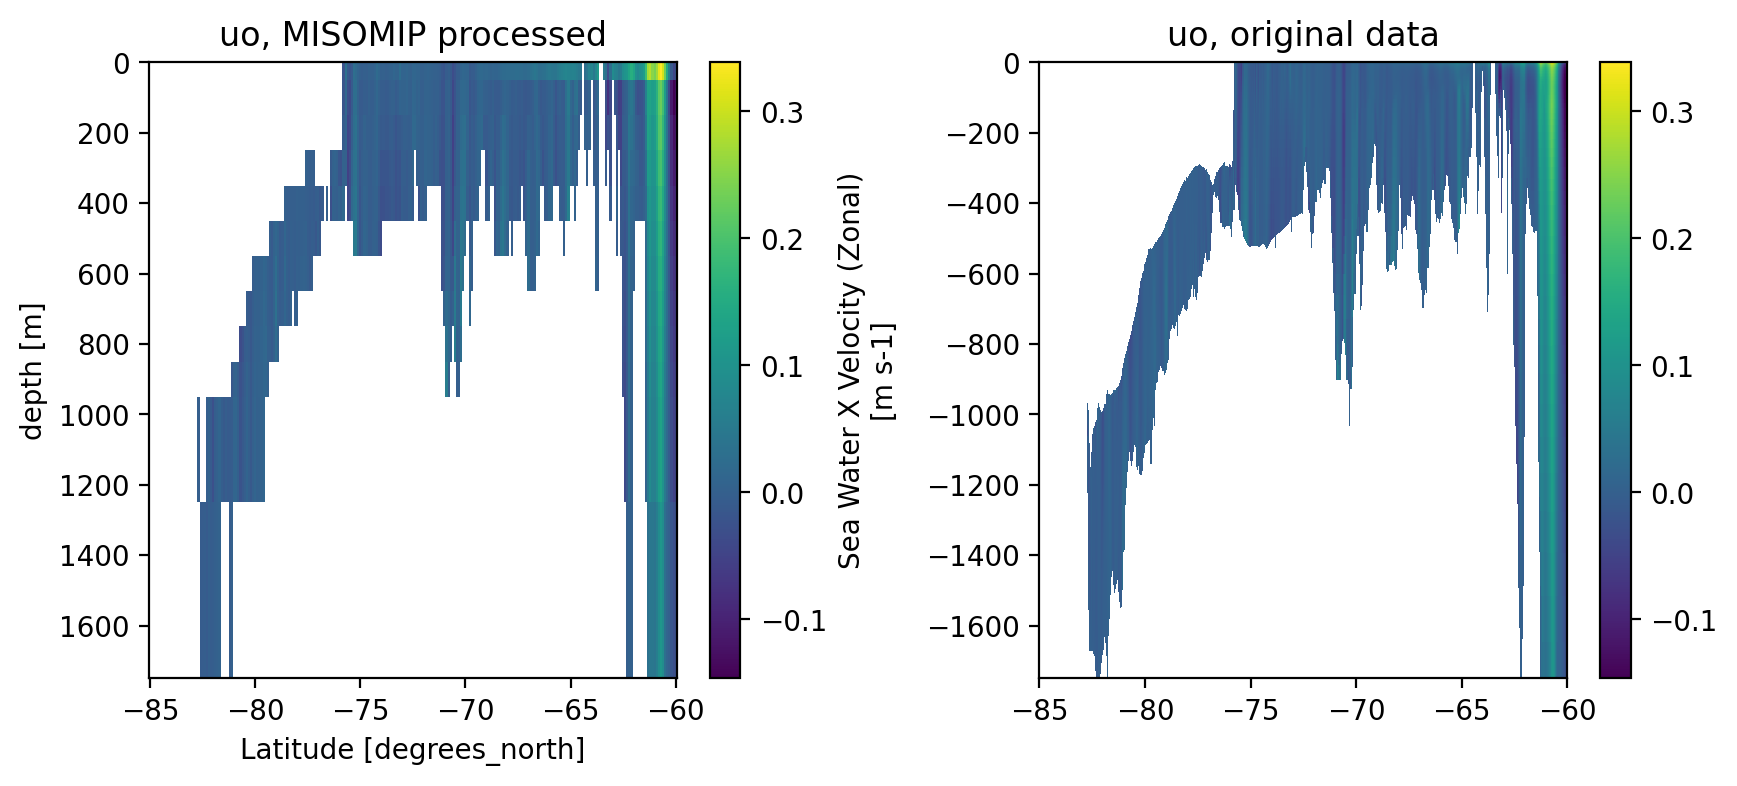

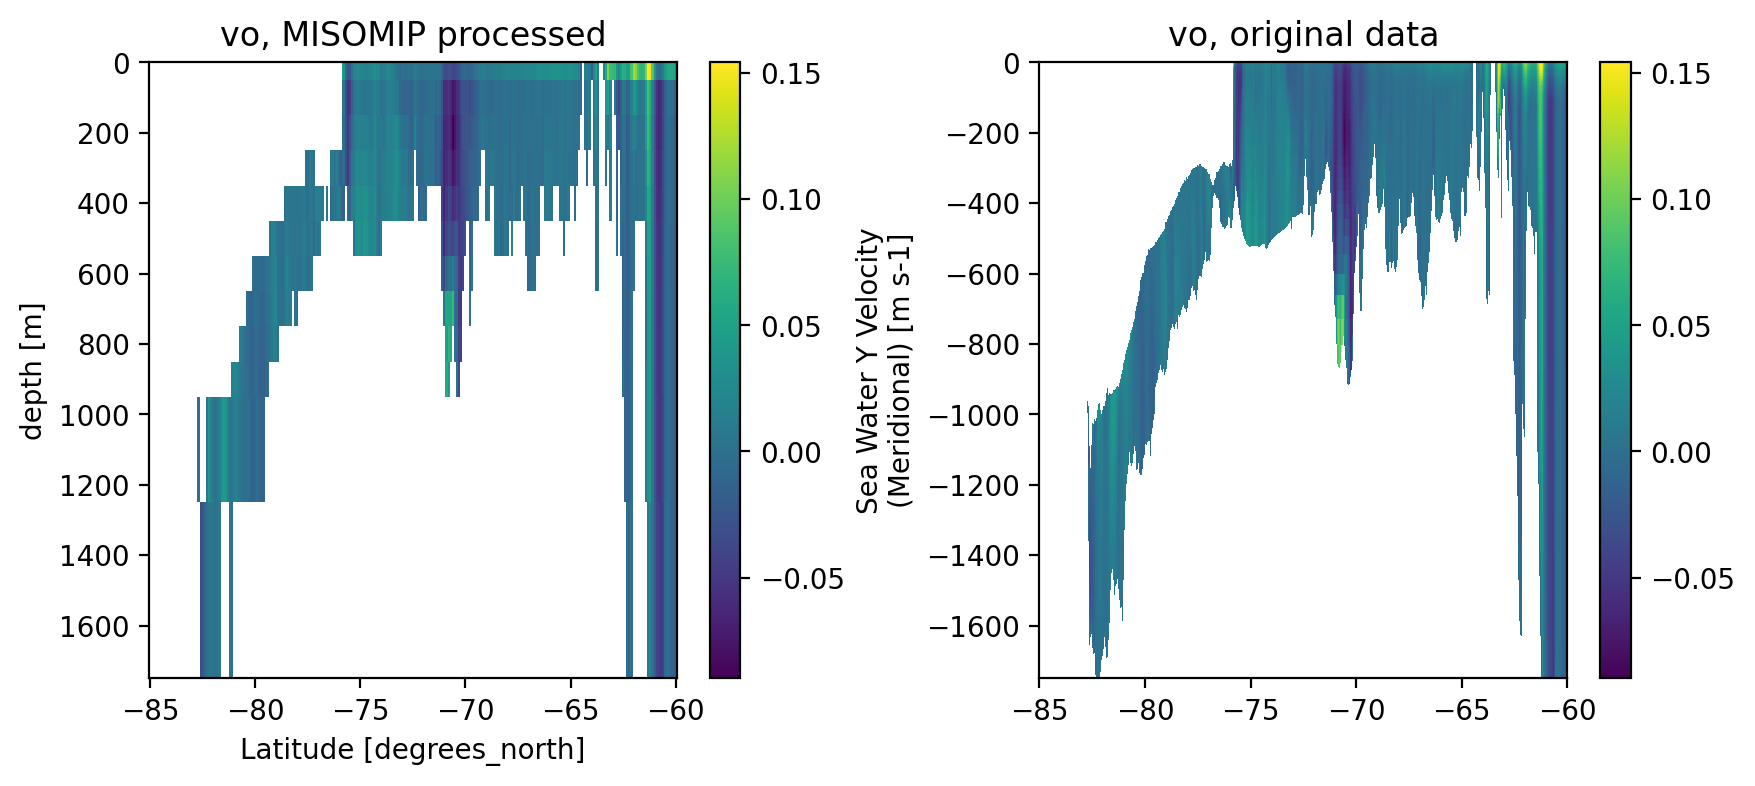

In [20]:
target_lon = -57

var_dict = {'thetao':{'ds': ncT, 'mom_var':  'temp'},
            'so':{'ds': ncT, 'mom_var':  'salt'},
            'uo':{'ds': ncU, 'mom_var': 'uo' },
            'vo':{'ds': ncV, 'mom_var': 'vo' },
            }

for ekey in var_dict.keys():
    fig, axes = plt.subplots(ncols = 2, figsize = (10,4),dpi = 200)
    var1 = ds[ekey].isel(time = 0).sel(lon = target_lon, method = 'nearest')
    vmax = var1.max().values
    vmin = var1.min().values
    
    var1.plot(ax = axes[0], vmax = vmax, vmin = vmin, yincrease = False)
    axes[0].set_title(ekey+', MISOMIP processed')
    axes[0].set_ylim(1750,0)

    temp_ds = var_dict[ekey]['ds']
    var = temp_ds[var_dict[ekey]['mom_var']].isel(time = 0)
    
    e = ncT.e.isel(time = 0)
    grid = xgcm.Grid(ncM, 
                     coords = {"x":{"center":"xh","outer":"xq"},
                                 "y":{"center":"yh","outer":"yq"}},
                     periodic = "x",
                     autoparse_metadata = False)
    e_on_yq = grid.interp(e,"y")
    
    if ekey in ['thetao','so']:
        transect = var.sel(xh = target_lon, method = 'nearest')
        # define y positions
        yqs,zis = np.meshgrid(e_on_yq.yq,e_on_yq.z_i)
        # define depth positions
        etas = e_on_yq.sel(xh = target_lon, method = 'nearest').bfill("yq").bfill("z_i").ffill("yq").ffill("z_i")
        
        
        # use pcolormesh to plot
        c = axes[1].pcolormesh(yqs,etas,transect, vmax = vmax, vmin = vmin)
    elif ekey in ['uo']:
        transect = var.sel(xq = target_lon, method = 'nearest')
        # define y positions
        yqs,zis = np.meshgrid(e_on_yq.yq,e_on_yq.z_i)
        # define depth positions
        etas = e_on_yq.sel(xh = target_lon, method = 'nearest').bfill("yq").bfill("z_i").ffill("yq").ffill("z_i")
        
        
        # use pcolormesh to plot
        c = axes[1].pcolormesh(yqs,etas,transect, vmax = vmax, vmin = vmin)
    elif ekey in ['vo']:
        transect = var.sel(xh = target_lon, method = 'nearest')[:,1:-1]
        # define y positions
        yqs,zis = np.meshgrid(e.yh,e.z_i)
        # define depth positions
        etas = e.sel(xh = target_lon, method = 'nearest').bfill("yh").bfill("z_i").ffill("yh").ffill("z_i")
        
        
        # use pcolormesh to plot
        c = axes[1].pcolormesh(yqs,etas,transect, vmax = vmax, vmin = vmin)

    plt.colorbar(c, ax = axes[1])
    axes[1].set_ylim(-1750,0)
    axes[1].set_xlim(-85,-60)
    axes[1].set_title(var_dict[ekey]['mom_var']+', original data')
    fig.subplots_adjust(wspace = 0.35)    
    plt.show()

# Check sections and moorings

Combine with

```
module load nco
ncrcat Oce3d_ANU_MOM6_a_OceanW-hind_19850* Oce3d_ANU_MOM6_a_OceanW-hind_198501-198508.nc
ncrcat OceSec1_ANU_MOM6_a_OceanW-hind_19850* OceSec1_ANU_MOM6_a_OceanW-hind_198501-198508.nc
ncrcat OceMoor1_ANU_MOM6_a_OceanW-hind_19850* OceMoor1_ANU_MOM6_a_OceanW-hind_198501-198508.nc
```



In [31]:
savepath = '/path/to/saved_data/'

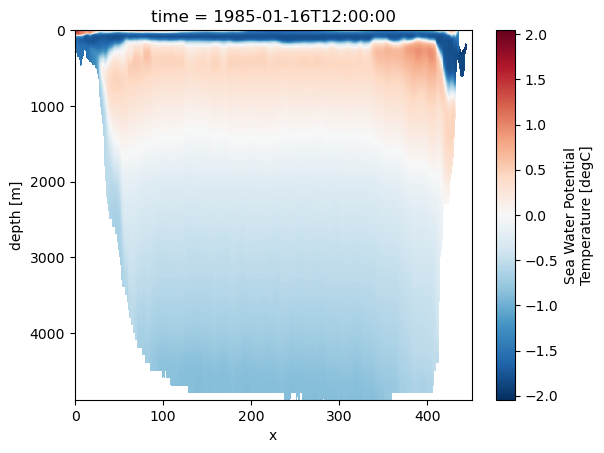

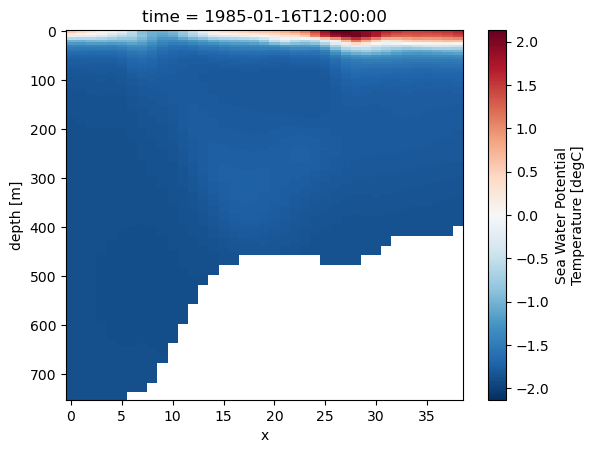

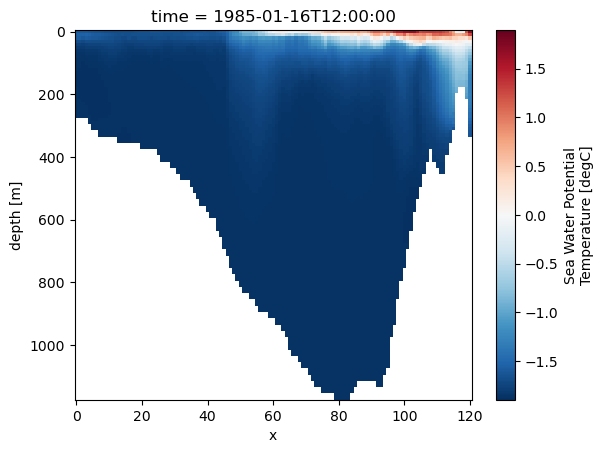

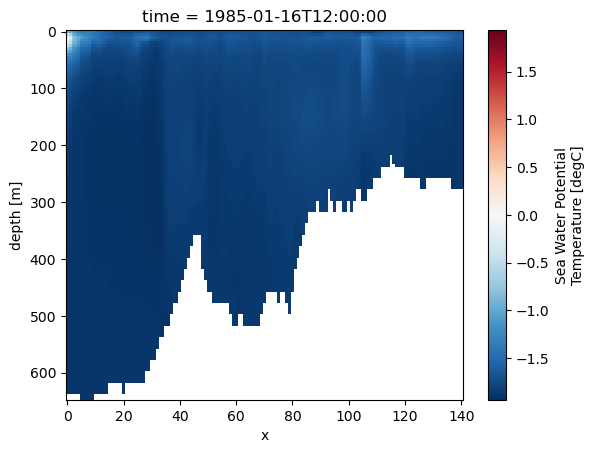

In [32]:
for sec in np.arange(1,5):
    testSec = xr.open_dataset(savepath+'combined/OceSec'+str(sec)+'_ANU_MOM6_a_OceanW-hind_198501-201812.nc')
    testSec.thetao.isel(time = 0).plot(yincrease = False)
    plt.show()

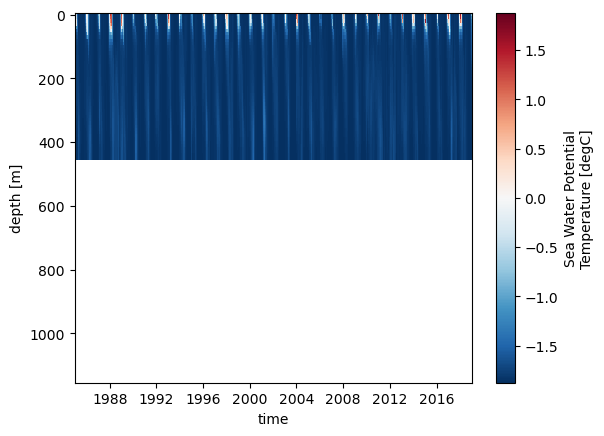

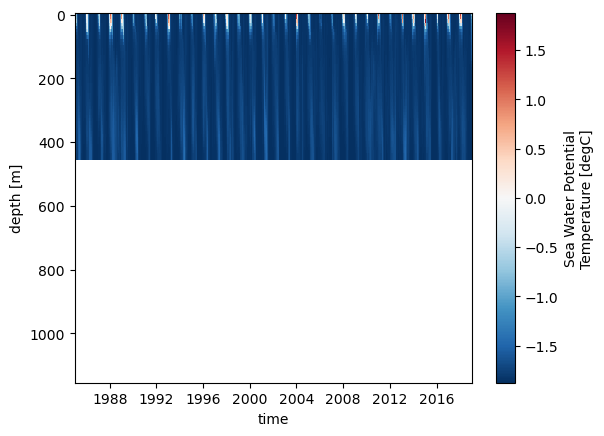

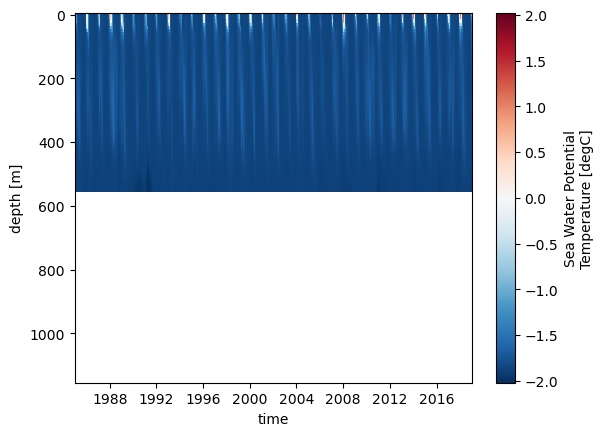

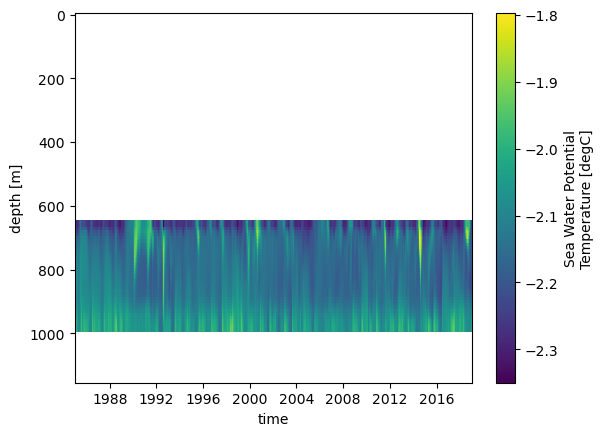

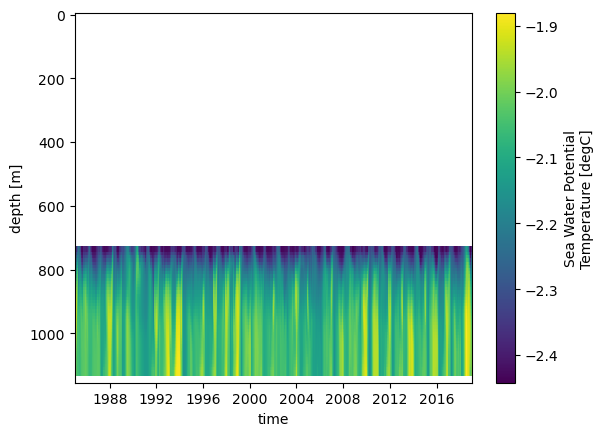

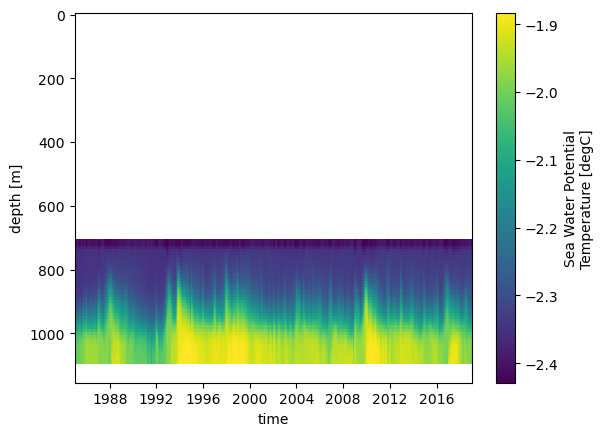

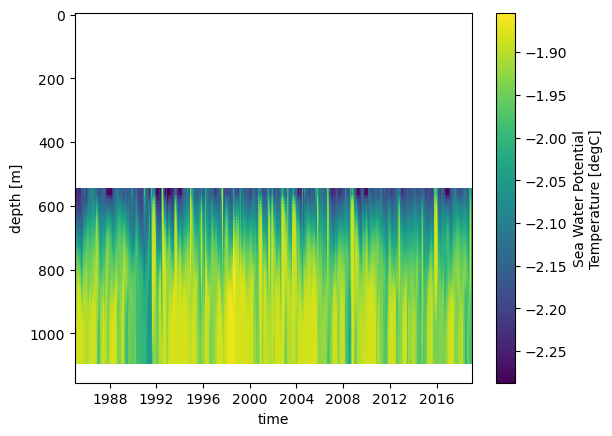

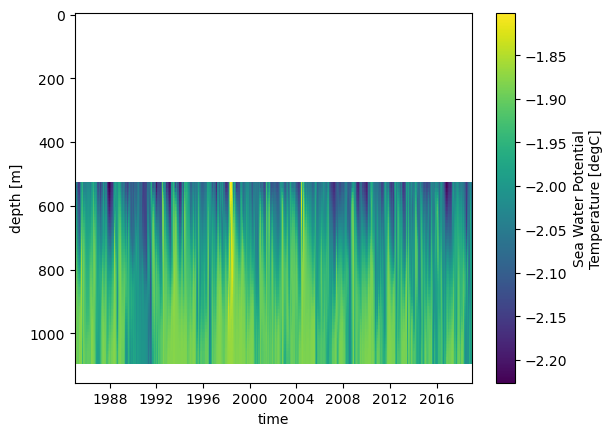

In [33]:
for mooring in np.arange(1,9):
    testMoor = xr.open_dataset(savepath+'combined/OceMoor'+str(mooring)+'_ANU_MOM6_a_OceanW-hind_198501-201812.nc')
    testMoor.thetao.plot(x = 'time', yincrease = False)
    plt.show()